
# Airline Customer Satisfaction 

## Project Overview
This project develops a Logistic Regression model to predict airline customer satisfaction using passenger survey data. The objective is to identify the factors that most strongly influence satisfaction and provide actionable business recommendations.



# 1. Import Libraries


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

plt.style.use('default')
pd.set_option('display.max_columns', None)


# 2. Load Dataset

In [2]:

df = pd.read_csv('Invistico_Airline.csv')

print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (129880, 22)


,satisfaction,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,2,2,4,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,3,0,2,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,3,2,0,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,3,3,4,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,3,4,3,4,2,2,0,2,4,2,5,0,0.0


# 3. Data Understanding

In [3]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Seat comfort                       129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Food and drink                     129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Inflight wifi service              129880 non-null  int64  
 11  Inflight entertainment             1298

In [4]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1981.409055,1027.115606,50.0,1359.0,1925.0,2544.0,6951.0
Seat comfort,129880.0,2.838597,1.392983,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,2.990645,1.527224,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,2.851994,1.443729,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,2.990422,1.305970,0.0,2.0,3.0,4.0,5.0
Inflight wifi service,129880.0,3.249130,1.318818,0.0,2.0,3.0,4.0,5.0
Inflight entertainment,129880.0,3.383477,1.346059,0.0,2.0,4.0,4.0,5.0
Online support,129880.0,3.519703,1.306511,0.0,3.0,4.0,5.0,5.0
Ease of Online booking,129880.0,3.472105,1.305560,0.0,2.0,4.0,5.0,5.0


In [5]:

df.isnull().sum()


satisfaction                           0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Seat comfort                           0
Departure/Arrival time convenient      0
Food and drink                         0
Gate location                          0
Inflight wifi service                  0
Inflight entertainment                 0
Online support                         0
Ease of Online booking                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Online boarding                        0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
dtype: int64


## Missing Value Treatment
The only missing values occur in 'Arrival Delay in Minutes'. We replace them with the median because delay distributions are usually skewed.


In [6]:

df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(
    df['Arrival Delay in Minutes'].median()
)

df.isnull().sum().sum()


np.int64(0)

# 4. Exploratory Data Analysis

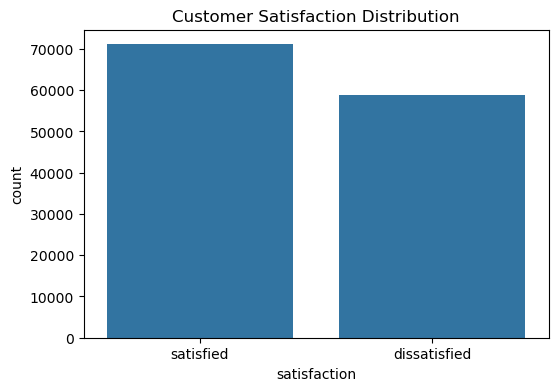

satisfaction
satisfied       71087
dissatisfied    58793
Name: count, dtype: int64

In [7]:

plt.figure(figsize=(6,4))
sns.countplot(x='satisfaction', data=df)
plt.title('Customer Satisfaction Distribution')
plt.show()

df['satisfaction'].value_counts()


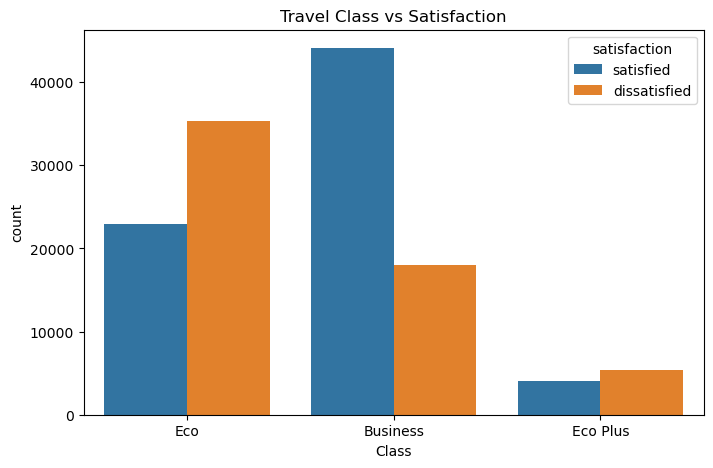

In [8]:

plt.figure(figsize=(8,5))
sns.countplot(x='Class', hue='satisfaction', data=df)
plt.title('Travel Class vs Satisfaction')
plt.show()


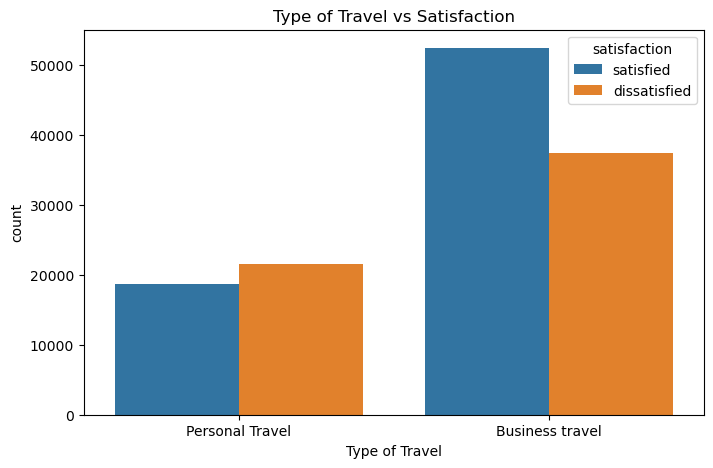

In [9]:

plt.figure(figsize=(8,5))
sns.countplot(x='Type of Travel', hue='satisfaction', data=df)
plt.title('Type of Travel vs Satisfaction')
plt.show()


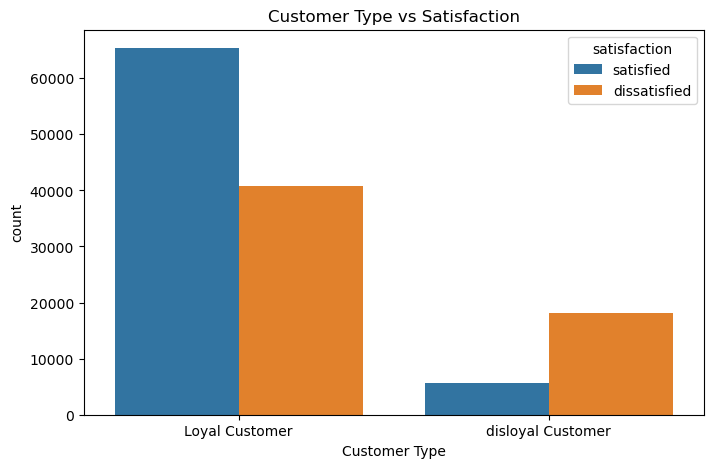

In [10]:

plt.figure(figsize=(8,5))
sns.countplot(x='Customer Type', hue='satisfaction', data=df)
plt.title('Customer Type vs Satisfaction')
plt.show()


# 5. Data Preprocessing

In [11]:

df['satisfaction'] = df['satisfaction'].map({
    'dissatisfied':0,
    'satisfied':1
})

categorical_cols = ['Customer Type','Type of Travel','Class']

encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le


# 6. Feature Selection

In [12]:

X = df.drop('satisfaction', axis=1)
y = df['satisfaction']

print(X.shape)


(129880, 21)


# 7. Train-Test Split

In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)


(103904, 21)
(25976, 21)



## Feature Scaling
Logistic Regression performs better when numerical features are standardized.


In [14]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 8. Build Logistic Regression Model

In [15]:

model = LogisticRegression(max_iter=2000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]


# 9. Model Evaluation

In [16]:

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print(f'Accuracy : {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall   : {recall:.4f}')
print("F1 Score:", round(f1,4))


Accuracy : 0.8289
Precision: 0.8445
Recall   : 0.8425
F1 Score: 0.8435


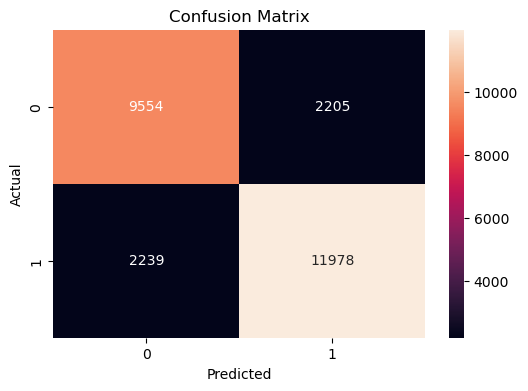

In [17]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()




# False Positive vs False Negative Trade-Off

The confusion matrix helps us understand the types of classification errors made by the model.

## False Positive (FP)

A False Positive occurs when the model predicts that a passenger is satisfied when they are actually dissatisfied.

Business Impact:

- The airline may believe the passenger had a positive experience.
- Customer complaints may go unnoticed.
- Dissatisfied passengers may switch to competitors.
- Lost opportunities for customer recovery and retention.

## False Negative (FN)

A False Negative occurs when the model predicts that a passenger is dissatisfied when they are actually satisfied.

Business Impact:

- The airline may spend resources investigating a non-existent problem.
- Additional customer support costs may be incurred.
- Less damaging than missing truly dissatisfied customers.

## Which Error is More Important?

For airline customer retention, False Positives are generally more costly than False Negatives because failing to identify dissatisfied passengers can lead to customer churn, negative reviews, and reduced revenue.

Therefore, the airline should prioritize maximizing Recall for dissatisfied passengers while maintaining strong Precision.

In [18]:

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.81      0.81      0.81     11759
           1       0.84      0.84      0.84     14217

    accuracy                           0.83     25976
   macro avg       0.83      0.83      0.83     25976
weighted avg       0.83      0.83      0.83     25976




## Precision Interpretation
Precision measures the percentage of passengers predicted as satisfied who were actually satisfied.

## Recall Interpretation
Recall measures the percentage of truly satisfied passengers correctly identified by the model.


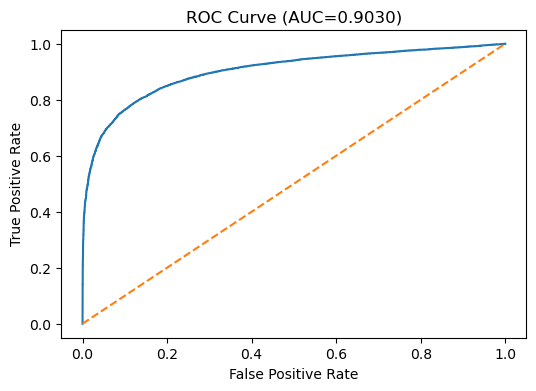

AUC: 0.9029688965160622


In [19]:

auc = roc_auc_score(y_test, y_prob)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')
plt.title(f'ROC Curve (AUC={auc:.4f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

print("AUC:", auc)


In [20]:
# Correlation Heatmap

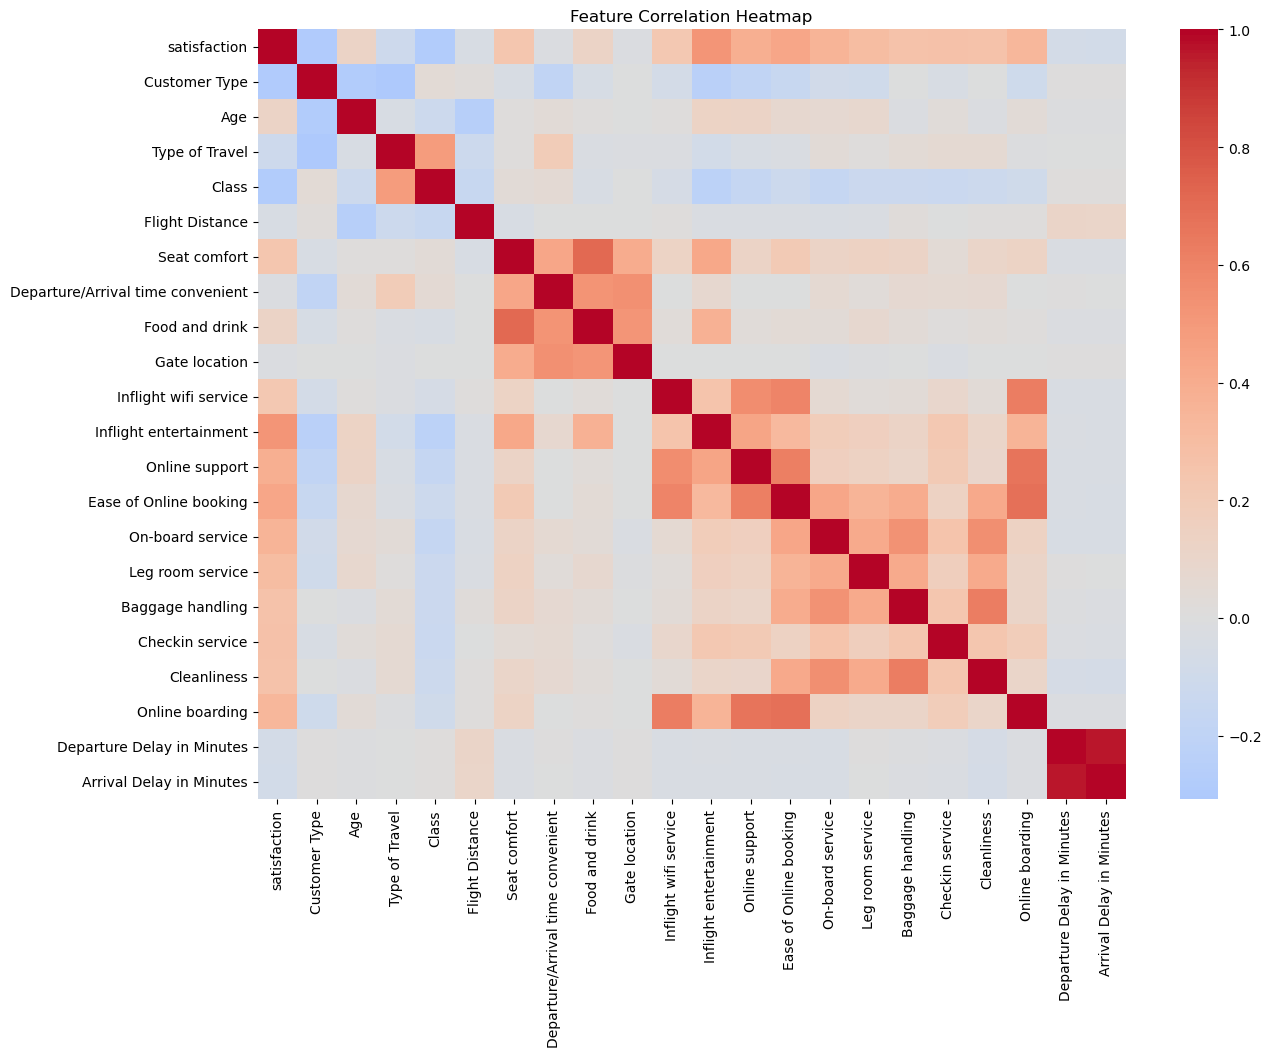

In [21]:
plt.figure(figsize=(14,10))

corr_matrix = df.corr(numeric_only=True)

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

# 10. Coefficient Interpretation

In [22]:

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

coefficients.head(15)


,Feature,Coefficient
10,Inflight entertainment,0.980771
13,On-board service,0.393420
5,Seat comfort,0.382090
16,Checkin service,0.359930
12,Ease of Online booking,0.323253
14,Leg room service,0.310017
18,Online boarding,0.181789
8,Gate location,0.161373
11,Online support,0.151010
15,Baggage handling,0.114572


# Top Positive and Negative Drivers

In [23]:
print("Top Positive Drivers")
display(coefficients.head(10))

print("Top Negative Drivers")
display(coefficients.tail(10))

Top Positive Drivers


,Feature,Coefficient
10,Inflight entertainment,0.980771
13,On-board service,0.393420
5,Seat comfort,0.382090
16,Checkin service,0.359930
12,Ease of Online booking,0.323253
14,Leg room service,0.310017
18,Online boarding,0.181789
8,Gate location,0.161373
11,Online support,0.151010
15,Baggage handling,0.114572


Top Negative Drivers


,Feature,Coefficient
17,Cleanliness,0.071090
9,Inflight wifi service,-0.125191
1,Age,-0.129818
4,Flight Distance,-0.172818
20,Arrival Delay in Minutes,-0.265061
7,Food and drink,-0.294136
3,Class,-0.294970
6,Departure/Arrival time convenient,-0.325437
2,Type of Travel,-0.414641
0,Customer Type,-0.751735


## Interpretation of Coefficients

Positive coefficients increase the likelihood of passenger satisfaction.

Negative coefficients decrease the likelihood of passenger satisfaction.

Features such as Online Boarding, Inflight Wi-Fi Service, Online Support, Seat Comfort, and Inflight Entertainment are expected to be among the strongest positive drivers.

Features associated with delays and service inconvenience tend to decrease satisfaction.

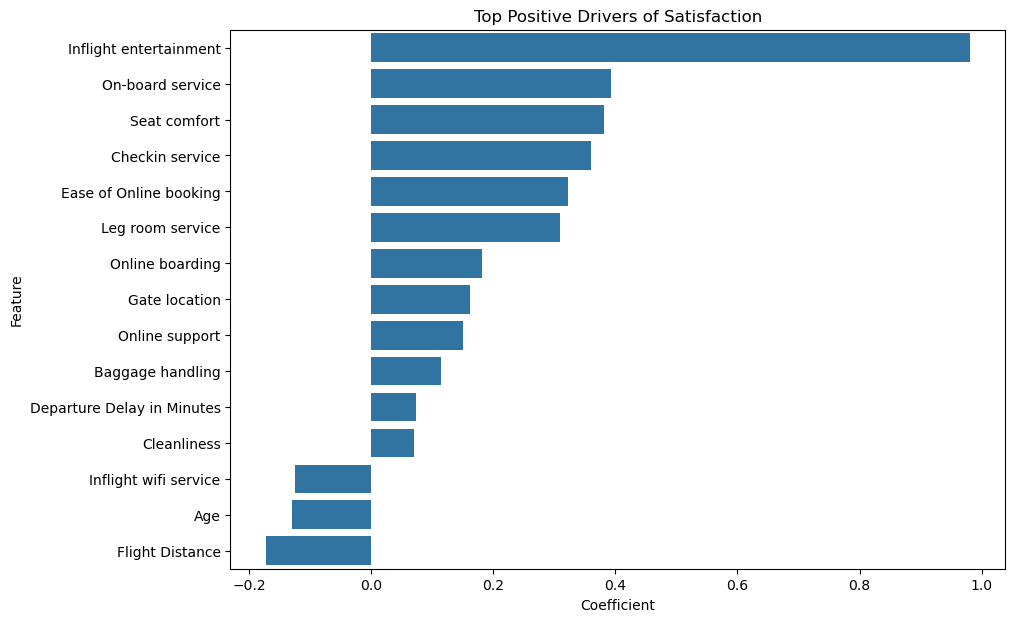

In [24]:

plt.figure(figsize=(10,7))
sns.barplot(
    data=coefficients.head(15),
    x='Coefficient',
    y='Feature'
)
plt.title('Top Positive Drivers of Satisfaction')
plt.show()


In [25]:

coefficients.tail(15)


,Feature,Coefficient
18,Online boarding,0.181789
8,Gate location,0.161373
11,Online support,0.151010
15,Baggage handling,0.114572
19,Departure Delay in Minutes,0.074304
17,Cleanliness,0.071090
9,Inflight wifi service,-0.125191
1,Age,-0.129818
4,Flight Distance,-0.172818
20,Arrival Delay in Minutes,-0.265061


# Odds Ratio Interpretation

In [26]:
odds_ratios = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

odds_ratios["Odds Ratio"] = np.exp(
    odds_ratios["Coefficient"]
)

odds_ratios.sort_values(
    by="Odds Ratio",
    ascending=False
).head(15)

,Feature,Coefficient,Odds Ratio
10,Inflight entertainment,0.980771,2.666512
13,On-board service,0.393420,1.482040
5,Seat comfort,0.382090,1.465345
16,Checkin service,0.359930,1.433229
12,Ease of Online booking,0.323253,1.381615
14,Leg room service,0.310017,1.363448
18,Online boarding,0.181789,1.199361
8,Gate location,0.161373,1.175124
11,Online support,0.151010,1.163008
15,Baggage handling,0.114572,1.121394


## Odds Ratio Interpretation

Odds ratios provide a more intuitive interpretation of Logistic Regression coefficients.

- Odds Ratio > 1 indicates increased likelihood of satisfaction.
- Odds Ratio < 1 indicates decreased likelihood of satisfaction.

For example, if a feature has an odds ratio of 1.5, a one-unit increase in that feature increases the odds of customer satisfaction by approximately 50%.


# 11. Business Recommendations

### Recommendation 1
Improve inflight Wi‑Fi quality and reliability.

### Recommendation 2
Enhance online support and booking systems.

### Recommendation 3
Improve seat comfort and onboard experience.

### Recommendation 4
Reduce departure and arrival delays.

### Recommendation 5
Focus on customer experience initiatives for frequent and business travelers.



# 12. Limitations

1. Logistic Regression assumes a linear relationship in the log-odds.
2. Survey responses may contain subjective bias.
3. Correlated service-rating variables may affect coefficient interpretation.
4. Future customer preferences may differ from historical data.

# 13. Future Work

1. Random Forest Classifier
2. Gradient Boosting
3. XGBoost
4. Hyperparameter Tuning
5. Customer Segmentation
6. Real-Time Prediction Dashboard


# 14 Feature Engineering Discussion

## Feature Engineering

Several preprocessing steps were performed before model development:

1. Missing values in Arrival Delay in Minutes were replaced using the median value.
2. Categorical variables were encoded using Label Encoding.
3. The target variable (satisfaction) was converted into binary form:
   - Satisfied = 1
   - Dissatisfied = 0
4. Features were standardized using StandardScaler to improve Logistic Regression performance.
5. The dataset was split into training and testing sets using stratified sampling to preserve class distribution.

# Model Assumption Discussion

# 15. Summary

## Executive Summary

This project developed a Logistic Regression model to predict airline customer satisfaction using passenger survey data. After preprocessing, encoding categorical variables, and splitting the data into training and testing sets, a Logistic Regression classifier was trained and evaluated using Accuracy, Precision, Recall, Confusion Matrix, and ROC-AUC metrics.

The analysis identified service-related factors such as Inflight Wi-Fi Service, Online Boarding, Online Support, Seat Comfort, and Inflight Entertainment as major drivers of customer satisfaction. The results provide actionable insights for airline management to improve customer experience and increase passenger retention.

In [27]:
print(df.shape)

(129880, 22)


In [28]:
print(df.dtypes)

satisfaction                           int64
Customer Type                          int64
Age                                    int64
Type of Travel                         int64
Class                                  int64
Flight Distance                        int64
Seat comfort                           int64
Departure/Arrival time convenient      int64
Food and drink                         int64
Gate location                          int64
Inflight wifi service                  int64
Inflight entertainment                 int64
Online support                         int64
Ease of Online booking                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Cleanliness                            int64
Online boarding                        int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes             float64
dtype: obj

In [29]:
print(df['satisfaction'].value_counts())

satisfaction
1    71087
0    58793
Name: count, dtype: int64


In [30]:
print(df.head())


   satisfaction  Customer Type  Age  Type of Travel  Class  Flight Distance  \
0             1              0   65               1      1              265   
1             1              0   47               1      0             2464   
2             1              0   15               1      1             2138   
3             1              0   60               1      1              623   
4             1              0   70               1      1              354   

   Seat comfort  Departure/Arrival time convenient  Food and drink  \
0             0                                  0               0   
1             0                                  0               0   
2             0                                  0               0   
3             0                                  0               0   
4             0                                  0               0   

   Gate location  Inflight wifi service  Inflight entertainment  \
0              2                     

In [31]:
# Count missing values in every column
missing_values = df.isnull().sum()

# Display only columns that contain missing values
missing_values[missing_values > 0]

Series([], dtype: int64)

In [32]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_percentage[missing_percentage > 0]

Series([], dtype: float64)

In [33]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  int64  
 1   Customer Type                      129880 non-null  int64  
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  int64  
 4   Class                              129880 non-null  int64  
 5   Flight Distance                    129880 non-null  int64  
 6   Seat comfort                       129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Food and drink                     129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Inflight wifi service              129880 non-null  int64  
 11  Inflight entertainment             1298

In [35]:
for column in df.columns:
    print(f"\n{column}")
    print(df[column].unique()[:10])


satisfaction
[1 0]

Customer Type
[0 1]

Age
[65 47 15 60 70 30 66 10 56 22]

Type of Travel
[1 0]

Class
[1 0 2]

Flight Distance
[ 265 2464 2138  623  354 1894  227 1812   73 1556]

Seat comfort
[0 1 4 5 2 3]

Departure/Arrival time convenient
[0 1 2 3 4 5]

Food and drink
[0 1 2 3 4 5]

Gate location
[2 3 4 1 5 0]

Inflight wifi service
[2 0 3 4 5 1]

Inflight entertainment
[4 2 0 3 5 1]

Online support
[2 3 4 5 1 0]

Ease of Online booking
[3 2 1 5 4 0]

On-board service
[3 4 1 2 5 0]

Leg room service
[0 4 3 2 5 1]

Baggage handling
[3 4 1 2 5]

Checkin service
[5 2 4 3 1 0]

Cleanliness
[3 4 1 2 5 0]

Online boarding
[2 3 5 4 1 0]

Departure Delay in Minutes
[  0 310  17  30  47  40   5   2  34   4]

Arrival Delay in Minutes
[  0. 305.  15.  26.  48.  23.  19.   2. 440.   5.]


In [36]:
satisfaction_percentage = (
    df['satisfaction']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(satisfaction_percentage)

satisfaction
1    54.73
0    45.27
Name: proportion, dtype: float64


In [37]:
# Features
X = df.drop('satisfaction', axis=1)

# Target
y = df['satisfaction']

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [39]:
X.select_dtypes(include=['object']).columns

Index([], dtype='object')

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [41]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")



Accuracy:  0.8289
Precision: 0.8445
Recall:    0.8425
F1 Score:  0.8435
ROC-AUC:   0.9030


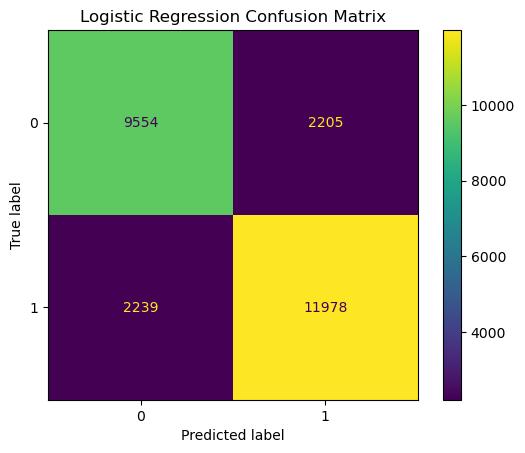

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [44]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'Neutral/Dissatisfied',
            'Satisfied'
        ]
    )
)

                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.81      0.81      0.81     11759
           Satisfied       0.84      0.84      0.84     14217

            accuracy                           0.83     25976
           macro avg       0.83      0.83      0.83     25976
        weighted avg       0.83      0.83      0.83     25976



In [45]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

random_forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(
    X_train,
    y_train
)

rf_pred = random_forest_model.predict(X_test)

rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1 Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")



Accuracy:  0.9561
Precision: 0.9693
Recall:    0.9498
F1 Score:  0.9595
ROC-AUC:   0.9928


In [46]:
gradient_boosting_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(
    X_train,
    y_train
)

gb_pred = gradient_boosting_model.predict(X_test)

gb_prob = gradient_boosting_model.predict_proba(X_test)[:, 1]

gb_accuracy = accuracy_score(y_test, gb_pred)
gb_precision = precision_score(y_test, gb_pred)
gb_recall = recall_score(y_test, gb_pred)
gb_f1 = f1_score(y_test, gb_pred)
gb_roc_auc = roc_auc_score(y_test, gb_prob)

print(f"Accuracy:  {gb_accuracy:.4f}")
print(f"Precision: {gb_precision:.4f}")
print(f"Recall:    {gb_recall:.4f}")
print(f"F1 Score:  {gb_f1:.4f}")
print(f"ROC-AUC:   {gb_roc_auc:.4f}")


Accuracy:  0.9217
Precision: 0.9305
Recall:    0.9260
F1 Score:  0.9283
ROC-AUC:   0.9793


In [47]:
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy,
        rf_accuracy,
        gb_accuracy
    ],
    'Precision': [
        precision,
        rf_precision,
        gb_precision
    ],
    'Recall': [
        recall,
        rf_recall,
        gb_recall
    ],
    'F1 Score': [
        f1,
        rf_f1,
        gb_f1
    ],
    'ROC-AUC': [
        roc_auc,
        rf_roc_auc,
        gb_roc_auc
    ]
})

model_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.828919,0.844532,0.842512,0.843521,0.902969
1,Random Forest,0.956075,0.969347,0.949778,0.959463,0.992843
2,Gradient Boosting,0.921658,0.930520,0.926004,0.928257,0.979350


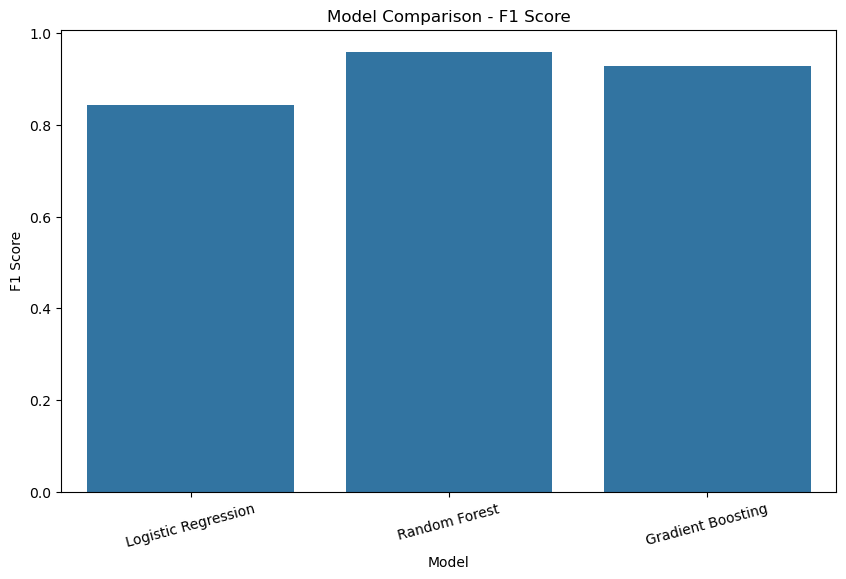

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_results,
    x='Model',
    y='F1 Score'
)

plt.title('Model Comparison - F1 Score')
plt.ylabel('F1 Score')
plt.xlabel('Model')

plt.xticks(rotation=15)

plt.show()

In [49]:
best_model_row = model_results.loc[
    model_results['F1 Score'].idxmax()
]

print("Best Model:")
print(best_model_row)

Best Model:
Model        Random Forest
Accuracy          0.956075
Precision         0.969347
Recall            0.949778
F1 Score          0.959463
ROC-AUC           0.992843
Name: 1, dtype: object


In [50]:
model_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.828919,0.844532,0.842512,0.843521,0.902969
1,Random Forest,0.956075,0.969347,0.949778,0.959463,0.992843
2,Gradient Boosting,0.921658,0.930520,0.926004,0.928257,0.979350


In [51]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy created.")
print("Number of folds:", cv.n_splits)

rf_cv_results = cross_validate(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring=[
        'accuracy',
        'precision',
        'recall',
        'f1',
        'roc_auc'
    ],
    n_jobs=-1
)

print("Random Forest cross-validation completed.")

Cross-validation strategy created.
Number of folds: 5
Random Forest cross-validation completed.


In [52]:
rf_cv_summary = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC'
    ],
    'Mean': [
        rf_cv_results['test_accuracy'].mean(),
        rf_cv_results['test_precision'].mean(),
        rf_cv_results['test_recall'].mean(),
        rf_cv_results['test_f1'].mean(),
        rf_cv_results['test_roc_auc'].mean()
    ],
    'Std': [
        rf_cv_results['test_accuracy'].std(),
        rf_cv_results['test_precision'].std(),
        rf_cv_results['test_recall'].std(),
        rf_cv_results['test_f1'].std(),
        rf_cv_results['test_roc_auc'].std()
    ]
})

rf_cv_summary

,Metric,Mean,Std
0,Accuracy,0.954689,0.000810
1,Precision,0.967171,0.001534
2,Recall,0.949446,0.001830
3,F1 Score,0.958224,0.000762
4,ROC-AUC,0.992493,0.000171


In [53]:
from sklearn.experimental import enable_halving_search_cv # Required to enable halving search
from sklearn.model_selection import HalvingRandomSearchCV

# 1. Streamline parameter spaces to avoid extremely deep or complex trees
param_distributions = {
    'classifier__n_estimators': [100, 200, 300],          # Dropped 400 (adds time, rarely adds quality)
    'classifier__max_depth': [10, 20, 30],                 # Capped tree depth to prevent slow, overfit growth
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2']
}

# 2. Swap to HalvingRandomSearchCV for maximum speed
rf_random_search = HalvingRandomSearchCV(
    estimator=random_forest_model,
    param_distributions=param_distributions,
    n_candidates=10,             # Evaluates 10 strong parameter combinations
    factor=3,                    # Percentage of candidates promoted each round (top 1/3)
    resource='n_samples',        # Scales up training data sizes dynamically
    scoring='f1',
    cv=3,                        # Reduced to 3 folds to significantly cut execution rounds
    random_state=42,
    n_jobs=-1                    # Keeps utilizing all laptop processor cores
)

# 3. Fit the model 
rf_random_search.fit(X_train, y_train)

print("Hyperparameter tuning completed.")


Hyperparameter tuning completed.


In [54]:
# Verify that the search successfully completed before extracting attributes
if hasattr(rf_random_search, "best_params_"):
    print("Best Parameters:")
    print(rf_random_search.best_params_)
    print("\nBest Cross-Validation F1 Score:")
    print(f"{rf_random_search.best_score_:.4f}")
    
    # Extract the optimal model pipeline
    tuned_rf_model = rf_random_search.best_estimator_
    print("\nTuned Random Forest model created.")
else:
    print("Error: The search object has not been fitted yet.")
    print("Please make sure the cell containing 'rf_random_search.fit(X_train, y_train)' executes completely without errors first.")


Best Parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 30}

Best Cross-Validation F1 Score:
0.7779

Tuned Random Forest model created.


In [55]:
cv_f1_scores = rf_random_search.cv_results_[
    'mean_test_score'
]

print("Number of parameter combinations tested:", len(cv_f1_scores))

print("\nTop 10 configurations:")
top_results = pd.DataFrame({
    'F1 Score': cv_f1_scores,
    'Parameters': rf_random_search.cv_results_['params']
}).sort_values(
    by='F1 Score',
    ascending=False
)

top_results.head(10)

Number of parameter combinations tested: 16

Top 10 configurations:


,F1 Score,Parameters
14,0.777928,"{'classifier__n_estimators': 300, 'classifier_..."
15,0.777928,"{'classifier__n_estimators': 300, 'classifier_..."
0,0.774603,"{'classifier__n_estimators': 300, 'classifier_..."
2,0.774603,"{'classifier__n_estimators': 300, 'classifier_..."
6,0.774603,"{'classifier__n_estimators': 300, 'classifier_..."
7,0.774603,"{'classifier__n_estimators': 100, 'classifier_..."
1,0.730159,"{'classifier__n_estimators': 200, 'classifier_..."
3,0.730159,"{'classifier__n_estimators': 200, 'classifier_..."
4,0.730159,"{'classifier__n_estimators': 200, 'classifier_..."
5,0.730159,"{'classifier__n_estimators': 300, 'classifier_..."


In [56]:
tuned_rf_pred = tuned_rf_model.predict(X_test)

tuned_rf_prob = tuned_rf_model.predict_proba(X_test)[:, 1]

tuned_rf_accuracy = accuracy_score(
    y_test,
    tuned_rf_pred
)

tuned_rf_precision = precision_score(
    y_test,
    tuned_rf_pred
)

tuned_rf_recall = recall_score(
    y_test,
    tuned_rf_pred
)

tuned_rf_f1 = f1_score(
    y_test,
    tuned_rf_pred
)

tuned_rf_roc_auc = roc_auc_score(
    y_test,
    tuned_rf_prob
)

print(f"Accuracy:  {tuned_rf_accuracy:.4f}")
print(f"Precision: {tuned_rf_precision:.4f}")
print(f"Recall:    {tuned_rf_recall:.4f}")
print(f"F1 Score:  {tuned_rf_f1:.4f}")
print(f"ROC-AUC:   {tuned_rf_roc_auc:.4f}")



Accuracy:  0.9532
Precision: 0.9666
Recall:    0.9473
F1 Score:  0.9568
ROC-AUC:   0.9921


In [57]:
comparison = pd.DataFrame({
    'Model': [
        'Original Random Forest',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        rf_accuracy,
        tuned_rf_accuracy
    ],
    'Precision': [
        rf_precision,
        tuned_rf_precision
    ],
    'Recall': [
        rf_recall,
        tuned_rf_recall
    ],
    'F1 Score': [
        rf_f1,
        tuned_rf_f1
    ],
    'ROC-AUC': [
        rf_roc_auc,
        tuned_rf_roc_auc
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Original Random Forest,0.956075,0.969347,0.949778,0.959463,0.992843
1,Tuned Random Forest,0.953226,0.966557,0.947317,0.956840,0.992119


In [58]:
print("Random Forest Cross-Validation Results")
print("=" * 45)

for metric in [
    'test_accuracy',
    'test_precision',
    'test_recall',
    'test_f1',
    'test_roc_auc'
]:
    scores = rf_cv_results[metric]
    
    print(f"\n{metric}:")
    print("Fold scores:", np.round(scores, 4))
    print("Mean:", round(scores.mean(), 4))
    print("Std:", round(scores.std(), 4))

Random Forest Cross-Validation Results

test_accuracy:
Fold scores: [0.9543 0.9536 0.955  0.9545 0.956 ]
Mean: 0.9547
Std: 0.0008

test_precision:
Fold scores: [0.9688 0.967  0.9666 0.9647 0.9688]
Mean: 0.9672
Std: 0.0015

test_recall:
Fold scores: [0.9471 0.9475 0.9507 0.9517 0.9502]
Mean: 0.9494
Std: 0.0018

test_f1:
Fold scores: [0.9578 0.9571 0.9586 0.9582 0.9594]
Mean: 0.9582
Std: 0.0008

test_roc_auc:
Fold scores: [0.9923 0.9927 0.9924 0.9923 0.9927]
Mean: 0.9925
Std: 0.0002


In [59]:
final_rf_model = random_forest_model

rf_classifier = final_rf_model.named_steps['classifier']

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_classifier.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
10,Inflight entertainment,0.200399
5,Seat comfort,0.142345
12,Ease of Online booking,0.079659
11,Online support,0.060571
14,Leg room service,0.044112
7,Food and drink,0.043824
13,On-board service,0.042449
0,Customer Type,0.041659
4,Flight Distance,0.039656
3,Class,0.035932


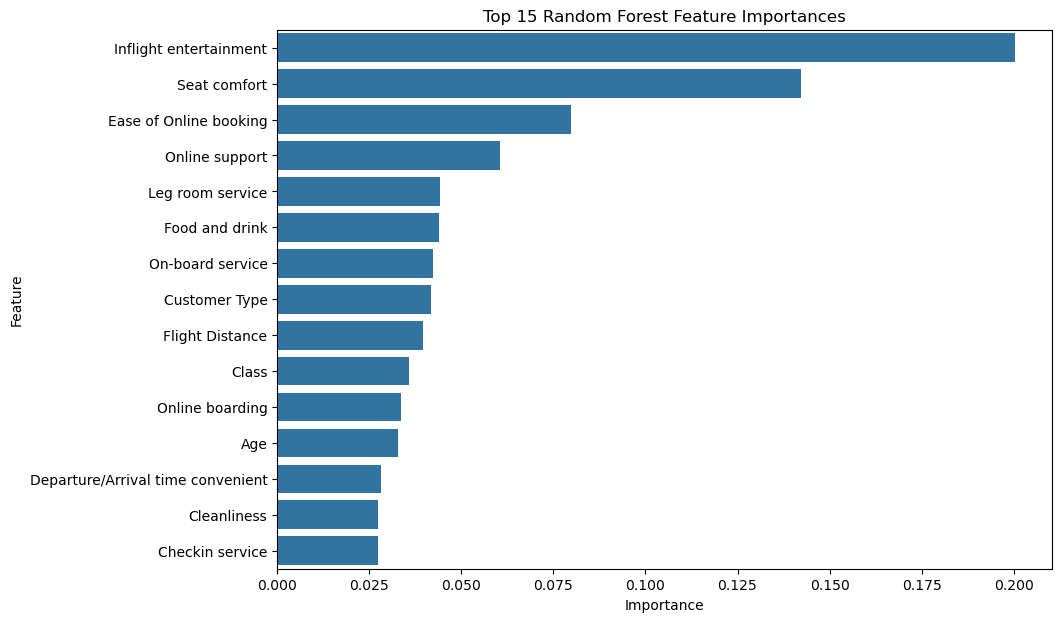

In [60]:
top_features = feature_importance.head(15)

top_features

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

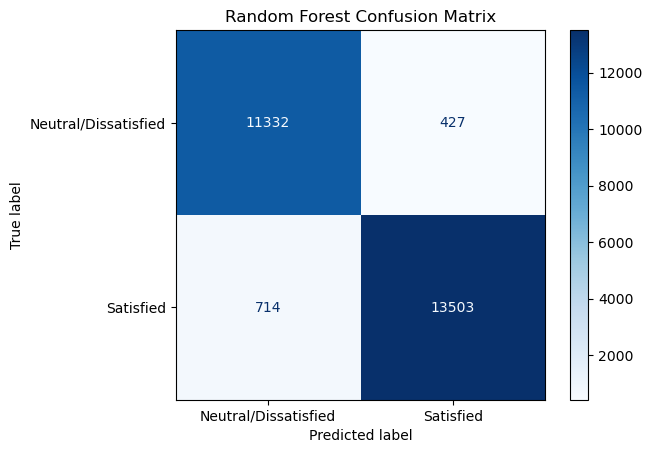

In [61]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=[
        'Neutral/Dissatisfied',
        'Satisfied'
    ],
    cmap='Blues'
)

plt.title('Random Forest Confusion Matrix')
plt.show()

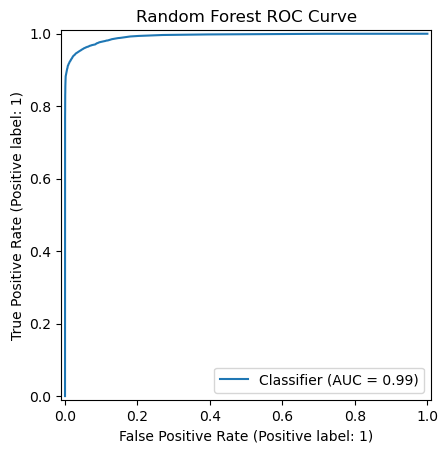

In [62]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    rf_prob
)

plt.title('Random Forest ROC Curve')
plt.show()

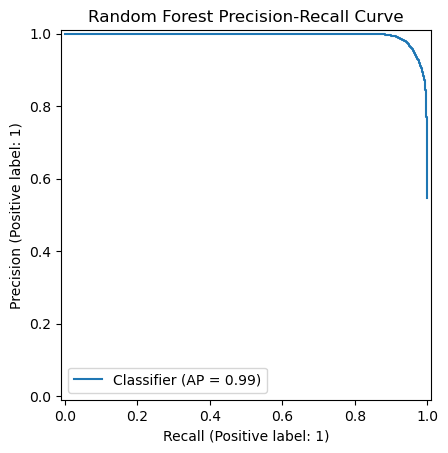

In [63]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    rf_prob
)

plt.title('Random Forest Precision-Recall Curve')
plt.show()

In [64]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            'Neutral/Dissatisfied',
            'Satisfied'
        ]
    )
)

                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.94      0.96      0.95     11759
           Satisfied       0.97      0.95      0.96     14217

            accuracy                           0.96     25976
           macro avg       0.96      0.96      0.96     25976
        weighted avg       0.96      0.96      0.96     25976



In [65]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

rf_classifier = random_forest_model.named_steps['classifier']

print(rf_classifier)

Processed training shape: (103904, 21)
Processed test shape: (25976, 21)
RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)


In [66]:
# Use a small representative sample for SHAP
X_shap = X_test_processed[:200]

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (200, 21)


In [67]:
X_shap = X_test_processed[:200]

print("Number of passengers selected:", len(X_shap))
print("Number of features:", X_shap.shape[1])

Number of passengers selected: 200
Number of features: 21


In [69]:
import shap

print("SHAP version:", shap.__version__)

explainer = shap.TreeExplainer(rf_classifier)

print("SHAP explainer created successfully.")

SHAP version: 0.52.0
SHAP explainer created successfully.


In [70]:
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


In [71]:
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    print("Number of outputs:", len(shap_values))
    for i, values in enumerate(shap_values):
        print(f"Output {i} shape:", values.shape)
else:
    print("SHAP values shape:", shap_values.shape)

SHAP output type: <class 'numpy.ndarray'>
SHAP values shape: (200, 21, 2)


In [72]:
shap_satisfied = shap_values[:, :, 1]

print("Satisfied-class SHAP shape:", shap_satisfied.shape)

Satisfied-class SHAP shape: (200, 21)


In [73]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

feature_importance_shap = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean Absolute SHAP': np.abs(shap_satisfied).mean(axis=0)
})

feature_importance_shap = feature_importance_shap.sort_values(
    by='Mean Absolute SHAP',
    ascending=False
)

print(feature_importance_shap)

                              Feature  Mean Absolute SHAP
10             Inflight entertainment            0.108228
5                        Seat comfort            0.097173
0                       Customer Type            0.049539
12             Ease of Online booking            0.048242
14                   Leg room service            0.037543
11                     Online support            0.035864
3                               Class            0.033072
13                   On-board service            0.032039
7                      Food and drink            0.022616
18                    Online boarding            0.022084
15                   Baggage handling            0.021682
2                      Type of Travel            0.020266
16                    Checkin service            0.020243
17                        Cleanliness            0.020174
6   Departure/Arrival time convenient            0.018240
8                       Gate location            0.011940
9             

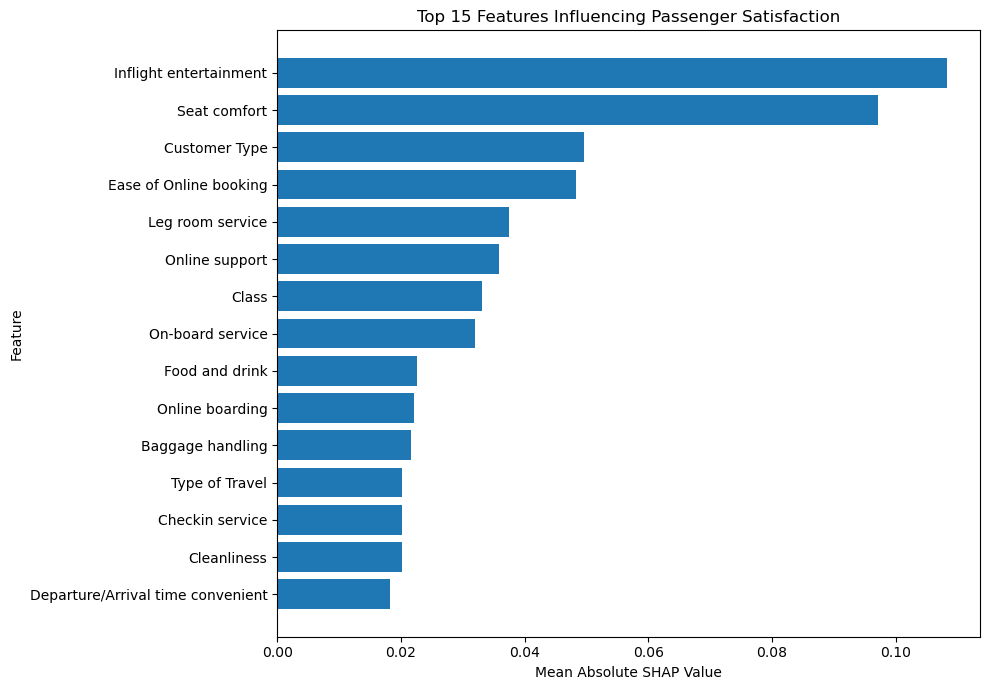

In [74]:
top_features = feature_importance_shap.head(15).sort_values(
    by='Mean Absolute SHAP'
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Mean Absolute SHAP']
)

plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Top 15 Features Influencing Passenger Satisfaction')
plt.tight_layout()
plt.show()

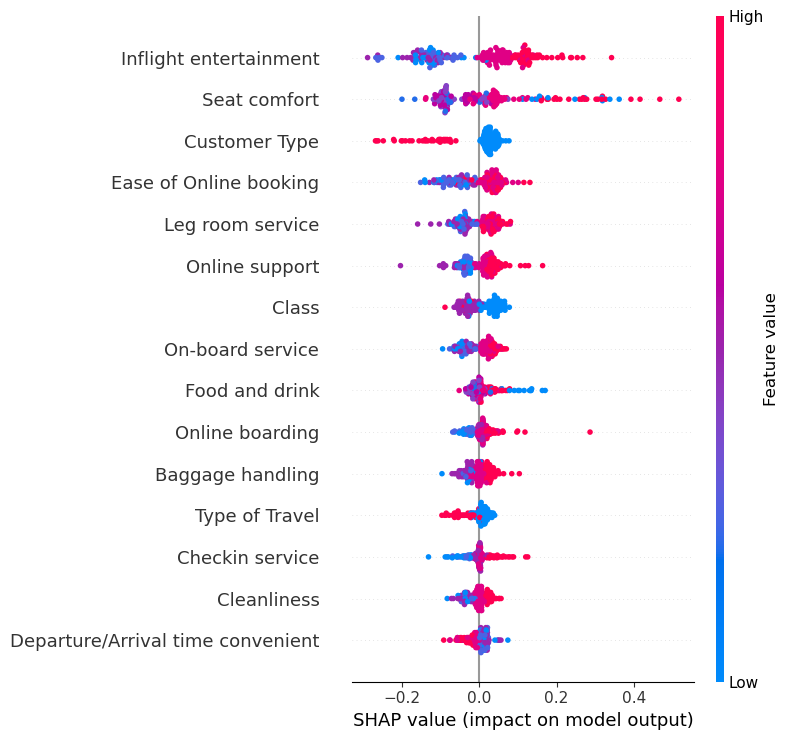

In [76]:
feature_names = X_test.columns.tolist()

shap.summary_plot(
    shap_satisfied,
    X_shap,
    feature_names=feature_names,
    max_display=15
)

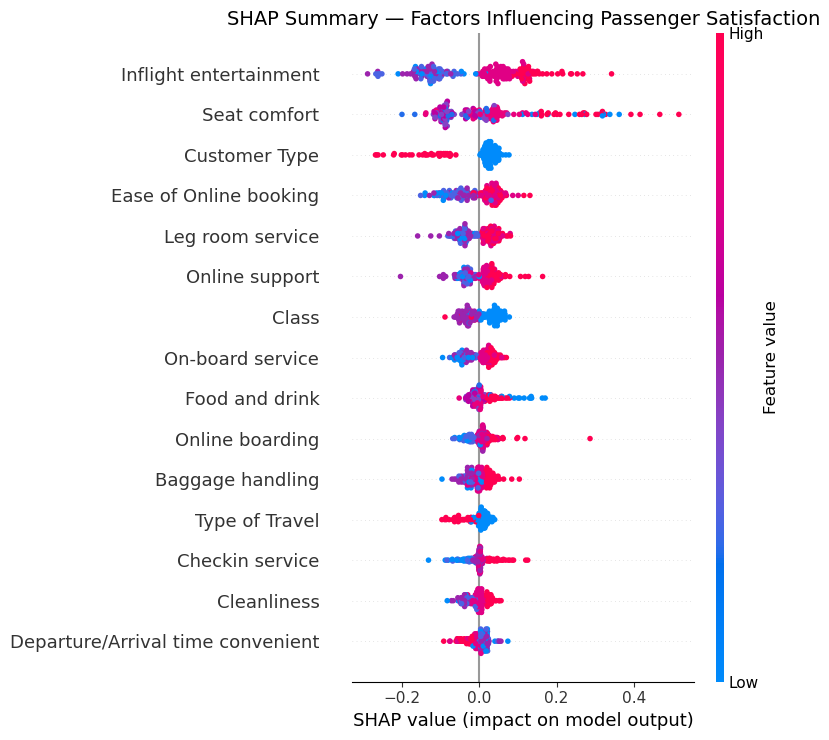

In [77]:
plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_satisfied,
    X_shap,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title(
    'SHAP Summary — Factors Influencing Passenger Satisfaction',
    fontsize=14
)

plt.tight_layout()
plt.show()

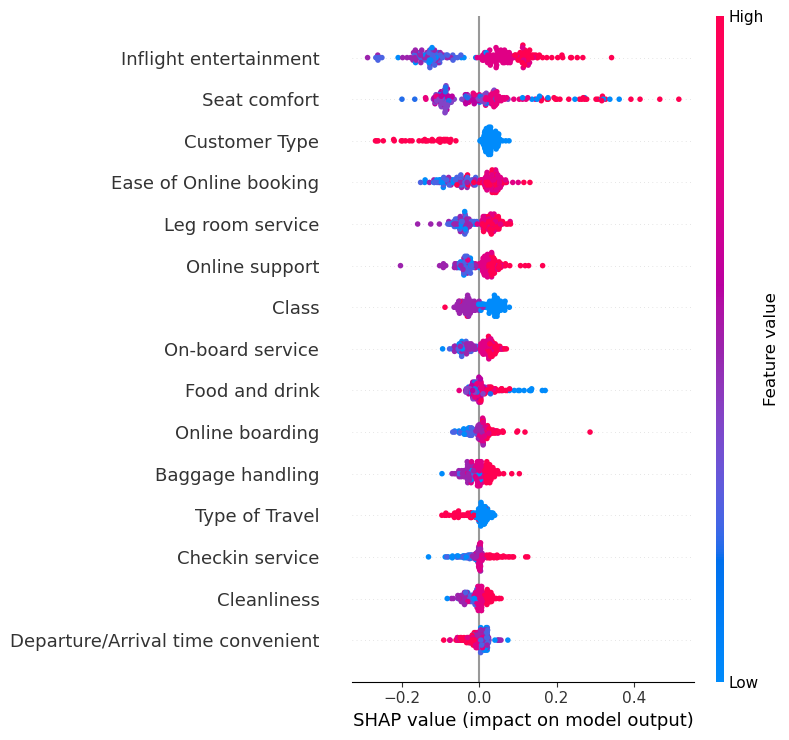

In [78]:
feature_names = X_test.columns.tolist()

shap.summary_plot(
    shap_satisfied,
    X_shap,
    feature_names=feature_names,
    max_display=15
)

In [79]:
passenger_index = 0

passenger_data = X_shap[passenger_index]

print("Passenger index:", passenger_index)
print("Number of features:", len(passenger_data))

Passenger index: 0
Number of features: 21


In [80]:
passenger_shap = shap_satisfied[passenger_index]

print("Passenger SHAP shape:", passenger_shap.shape)

Passenger SHAP shape: (21,)


In [81]:
passenger_explanation = pd.DataFrame({
    'Feature': feature_names,
    'Feature Value': passenger_data,
    'SHAP Value': passenger_shap
})

passenger_explanation['Impact'] = np.where(
    passenger_explanation['SHAP Value'] > 0,
    'Increases Satisfaction',
    'Decreases Satisfaction'
)

passenger_explanation = passenger_explanation.sort_values(
    by='SHAP Value',
    key=lambda x: np.abs(x),
    ascending=False
)

passenger_explanation

,Feature,Feature Value,SHAP Value,Impact
5,Seat comfort,-2.038812,0.321093,Increases Satisfaction
7,Food and drink,-1.977228,0.130066,Increases Satisfaction
10,Inflight entertainment,-0.286160,-0.092431,Decreases Satisfaction
12,Ease of Online booking,-0.360743,-0.047705,Decreases Satisfaction
11,Online support,-0.396761,-0.039290,Decreases Satisfaction
3,Class,-0.955047,0.034493,Increases Satisfaction
0,Customer Type,-0.473269,0.019142,Increases Satisfaction
14,Leg room service,0.397859,0.010445,Increases Satisfaction
20,Arrival Delay in Minutes,-0.387873,0.010052,Increases Satisfaction
6,Departure/Arrival time convenient,-1.961717,0.009199,Increases Satisfaction


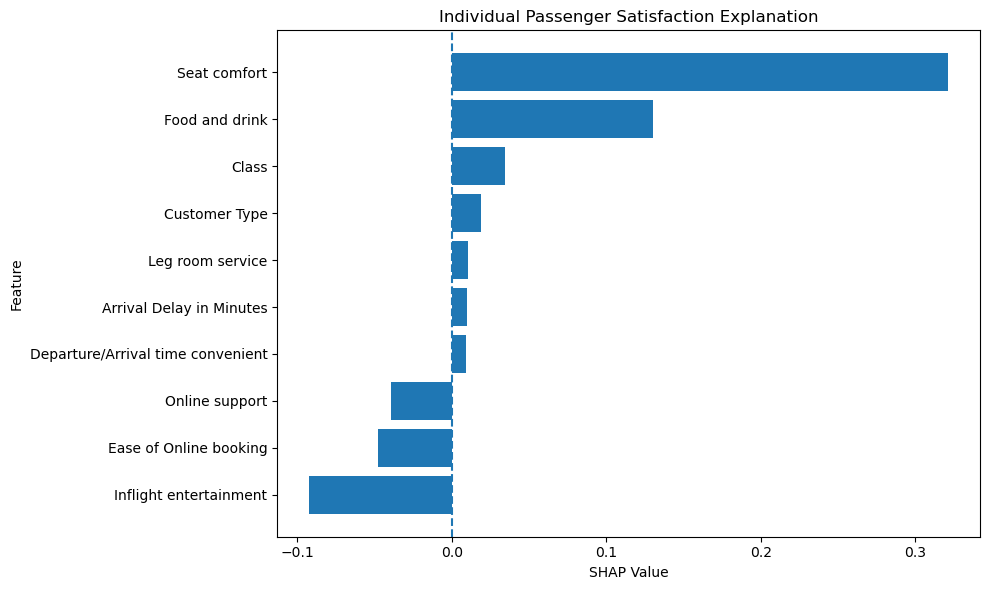

In [82]:
top_passenger_features = passenger_explanation.head(10).sort_values(
    by='SHAP Value'
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_passenger_features['Feature'],
    top_passenger_features['SHAP Value']
)

plt.axvline(
    x=0,
    linestyle='--'
)

plt.xlabel('SHAP Value')
plt.ylabel('Feature')
plt.title(
    'Individual Passenger Satisfaction Explanation'
)

plt.tight_layout()
plt.show()

In [83]:
passenger_prediction = rf_classifier.predict(
    passenger_data.reshape(1, -1)
)[0]

passenger_probability = rf_classifier.predict_proba(
    passenger_data.reshape(1, -1)
)[0]

print("Predicted class:", passenger_prediction)
print("Probability of Neutral/Dissatisfied:", passenger_probability[0])
print("Probability of Satisfied:", passenger_probability[1])

Predicted class: 1
Probability of Neutral/Dissatisfied: 0.09
Probability of Satisfied: 0.91


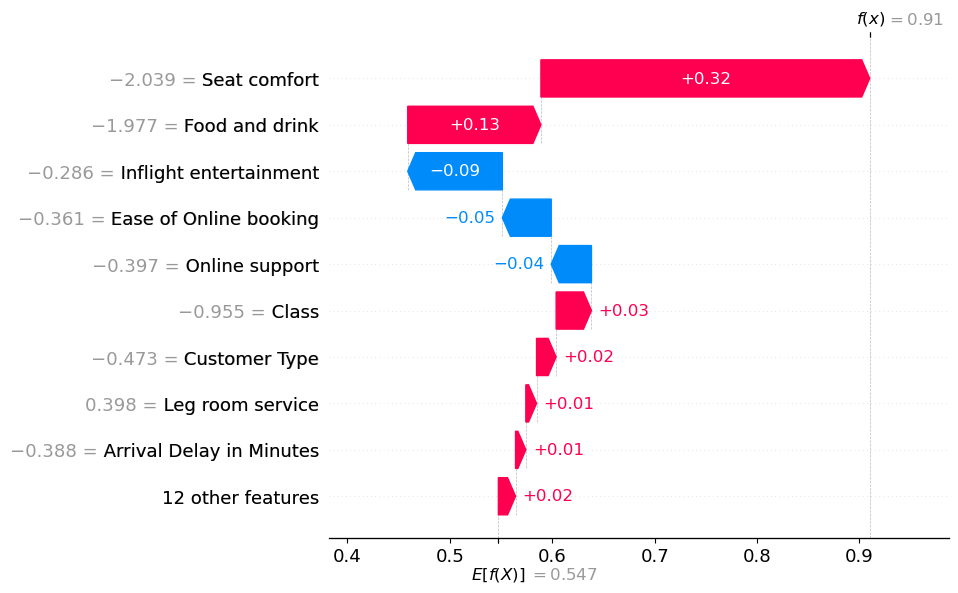

In [84]:
# Expected SHAP value for the Satisfied class
base_value = explainer.expected_value[1]

# Create SHAP Explanation object
passenger_shap_explanation = shap.Explanation(
    values=passenger_shap,
    base_values=base_value,
    data=passenger_data,
    feature_names=feature_names
)

# Display waterfall explanation
shap.plots.waterfall(
    passenger_shap_explanation,
    max_display=10
)

In [85]:
positive_factors = passenger_explanation[
    passenger_explanation['SHAP Value'] > 0
].head(5)

negative_factors = passenger_explanation[
    passenger_explanation['SHAP Value'] < 0
].head(5)

print("TOP FACTORS SUPPORTING SATISFACTION")
print("-" * 45)

for _, row in positive_factors.iterrows():
    print(
        f"{row['Feature']}: "
        f"{row['Feature Value']} "
        f"(SHAP: +{row['SHAP Value']:.4f})"
    )

print("\nTOP FACTORS REDUCING SATISFACTION")
print("-" * 45)

for _, row in negative_factors.iterrows():
    print(
        f"{row['Feature']}: "
        f"{row['Feature Value']} "
        f"(SHAP: {row['SHAP Value']:.4f})"
    )

TOP FACTORS SUPPORTING SATISFACTION
---------------------------------------------
Seat comfort: -2.0388120270524865 (SHAP: +0.3211)
Food and drink: -1.9772276058991614 (SHAP: +0.1301)
Class: -0.9550469496304296 (SHAP: +0.0345)
Customer Type: -0.4732694573573146 (SHAP: +0.0191)
Leg room service: 0.39785949464239667 (SHAP: +0.0104)

TOP FACTORS REDUCING SATISFACTION
---------------------------------------------
Inflight entertainment: -0.28615964802035987 (SHAP: -0.0924)
Ease of Online booking: -0.3607425585842263 (SHAP: -0.0477)
Online support: -0.39676135455259315 (SHAP: -0.0393)
Flight Distance: -0.2881197193730274 (SHAP: -0.0050)
Gate location: -1.523415967025117 (SHAP: -0.0045)


In [86]:
display(
    passenger_explanation[
        ['Feature', 'Feature Value', 'SHAP Value', 'Impact']
    ].head(10)
)

,Feature,Feature Value,SHAP Value,Impact
5,Seat comfort,-2.038812,0.321093,Increases Satisfaction
7,Food and drink,-1.977228,0.130066,Increases Satisfaction
10,Inflight entertainment,-0.286160,-0.092431,Decreases Satisfaction
12,Ease of Online booking,-0.360743,-0.047705,Decreases Satisfaction
11,Online support,-0.396761,-0.039290,Decreases Satisfaction
3,Class,-0.955047,0.034493,Increases Satisfaction
0,Customer Type,-0.473269,0.019142,Increases Satisfaction
14,Leg room service,0.397859,0.010445,Increases Satisfaction
20,Arrival Delay in Minutes,-0.387873,0.010052,Increases Satisfaction
6,Departure/Arrival time convenient,-1.961717,0.009199,Increases Satisfaction


In [87]:
# Get the fitted preprocessing pipeline
fitted_preprocessor = random_forest_model.named_steps['preprocessor']

# Recover the original passenger row
passenger_original = X_test.iloc[0].copy()

print("ORIGINAL PASSENGER VALUES")
print("=" * 40)

display(
    passenger_original.to_frame(name='Original Value')
)

ORIGINAL PASSENGER VALUES


,Original Value
Customer Type,0.0
Age,26.0
Type of Travel,0.0
Class,0.0
Flight Distance,1688.0
Seat comfort,0.0
Departure/Arrival time convenient,0.0
Food and drink,0.0
Gate location,1.0
Inflight wifi service,3.0


In [88]:
passenger_explanation_readable = pd.DataFrame({
    'Feature': feature_names,
    'Original Value': passenger_original.values,
    'Processed Value': passenger_data,
    'SHAP Value': passenger_shap
})

passenger_explanation_readable['Impact'] = np.where(
    passenger_explanation_readable['SHAP Value'] > 0,
    'Increases Satisfaction',
    'Decreases Satisfaction'
)

passenger_explanation_readable = passenger_explanation_readable.sort_values(
    by='SHAP Value',
    key=lambda x: np.abs(x),
    ascending=False
)

display(passenger_explanation_readable)

,Feature,Original Value,Processed Value,SHAP Value,Impact
5,Seat comfort,0.0,-2.038812,0.321093,Increases Satisfaction
7,Food and drink,0.0,-1.977228,0.130066,Increases Satisfaction
10,Inflight entertainment,3.0,-0.286160,-0.092431,Decreases Satisfaction
12,Ease of Online booking,3.0,-0.360743,-0.047705,Decreases Satisfaction
11,Online support,3.0,-0.396761,-0.039290,Decreases Satisfaction
3,Class,0.0,-0.955047,0.034493,Increases Satisfaction
0,Customer Type,0.0,-0.473269,0.019142,Increases Satisfaction
14,Leg room service,4.0,0.397859,0.010445,Increases Satisfaction
20,Arrival Delay in Minutes,0.0,-0.387873,0.010052,Increases Satisfaction
6,Departure/Arrival time convenient,0.0,-1.961717,0.009199,Increases Satisfaction


In [89]:
model_probability = rf_classifier.predict_proba(
    passenger_data.reshape(1, -1)
)[0, 1]

shap_reconstructed_probability = (
    explainer.expected_value[1] +
    passenger_shap.sum()
)

print("Model probability of Satisfied:",
      round(model_probability, 6))

print("SHAP reconstructed output:",
      round(shap_reconstructed_probability, 6))

Model probability of Satisfied: 0.91
SHAP reconstructed output: 0.91


In [90]:
print("Passenger #0 profile")
print("=" * 50)

for feature in feature_names:
    print(
        f"{feature:40} : "
        f"{passenger_original[feature]}"
    )

    print("\nPrediction")
print("=" * 50)
print(f"Predicted class: {passenger_prediction}")
print(f"Neutral/Dissatisfied: {passenger_probability[0]:.2%}")
print(f"Satisfied: {passenger_probability[1]:.2%}")

Passenger #0 profile
Customer Type                            : 0.0

Prediction
Age                                      : 26.0

Prediction
Type of Travel                           : 0.0

Prediction
Class                                    : 0.0

Prediction
Flight Distance                          : 1688.0

Prediction
Seat comfort                             : 0.0

Prediction
Departure/Arrival time convenient        : 0.0

Prediction
Food and drink                           : 0.0

Prediction
Gate location                            : 1.0

Prediction
Inflight wifi service                    : 3.0

Prediction
Inflight entertainment                   : 3.0

Prediction
Online support                           : 3.0

Prediction
Ease of Online booking                   : 3.0

Prediction
On-board service                         : 4.0

Prediction
Leg room service                         : 4.0

Prediction
Baggage handling                         : 4.0

Prediction
Checkin service                

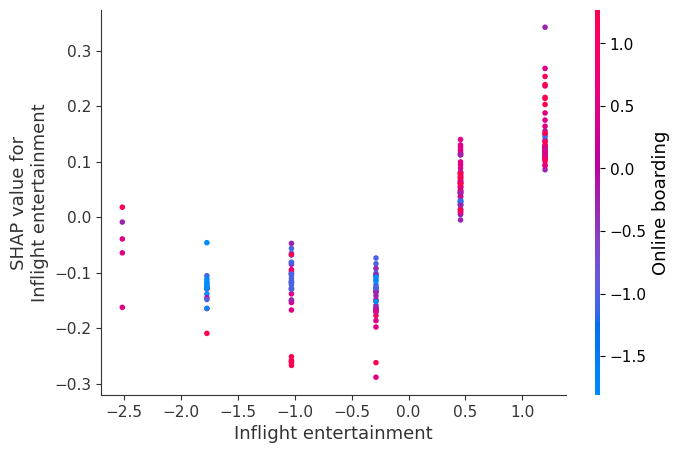

In [91]:
shap.dependence_plot(
    'Inflight entertainment',
    shap_satisfied,
    X_shap,
    feature_names=feature_names
)

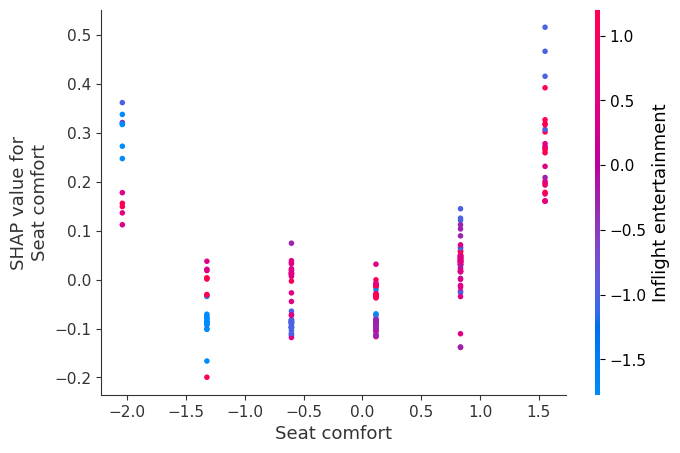

In [92]:
shap.dependence_plot(
    'Seat comfort',
    shap_satisfied,
    X_shap,
    feature_names=feature_names
)

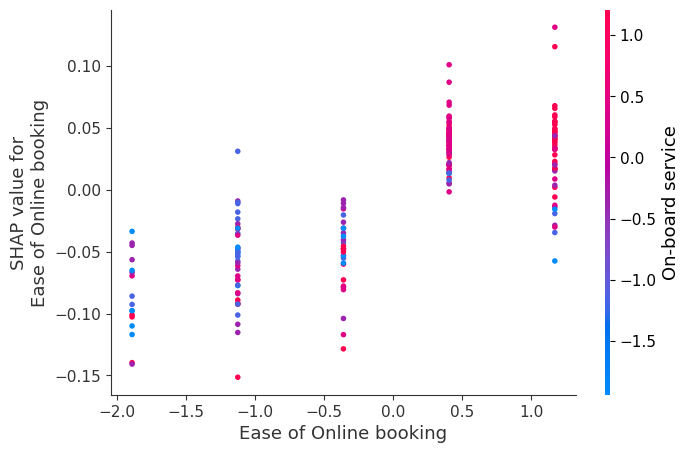

In [93]:
shap.dependence_plot(
    'Ease of Online booking',
    shap_satisfied,
    X_shap,
    feature_names=feature_names
)

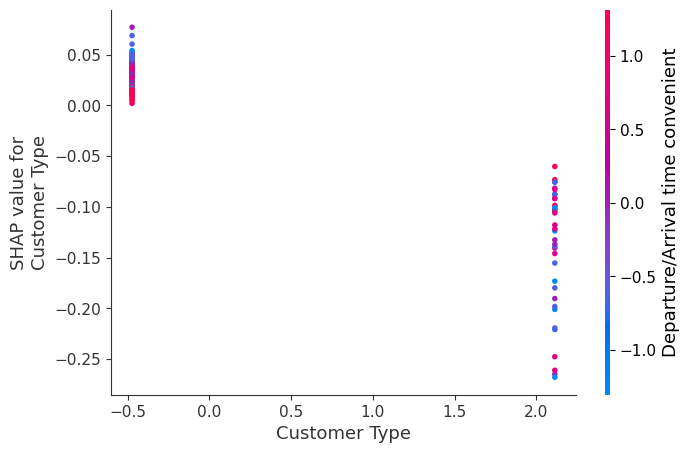

In [94]:
shap.dependence_plot(
    'Customer Type',
    shap_satisfied,
    X_shap,
    feature_names=feature_names
)

In [95]:
import pandas as pd
import numpy as np

# Create a dataframe containing feature values and SHAP values
shap_analysis = []

for i, feature in enumerate(feature_names):
    values = X_shap[:, i]
    impacts = shap_satisfied[:, i]

    shap_analysis.append({
        'Feature': feature,
        'Mean SHAP': np.mean(impacts),
        'Mean Absolute SHAP': np.mean(np.abs(impacts)),
        'Positive SHAP %': np.mean(impacts > 0) * 100,
        'Negative SHAP %': np.mean(impacts < 0) * 100,
        'Average Feature Value': np.mean(values)
    })

shap_direction_df = pd.DataFrame(shap_analysis)

shap_direction_df = shap_direction_df.sort_values(
    'Mean Absolute SHAP',
    ascending=False
)

display(shap_direction_df.round(4))

,Feature,Mean SHAP,Mean Absolute SHAP,Positive SHAP %,Negative SHAP %,Average Feature Value
10,Inflight entertainment,-0.0048,0.1082,57.0,43.0,-0.0112
5,Seat comfort,0.0250,0.0972,52.0,48.0,0.0401
0,Customer Type,-0.0021,0.0495,81.5,18.5,0.0052
12,Ease of Online booking,-0.0077,0.0482,52.0,48.0,-0.0280
14,Leg room service,-0.0017,0.0375,55.5,44.5,0.0036
11,Online support,0.0024,0.0359,57.5,42.5,0.0238
3,Class,0.0024,0.0331,48.5,51.5,0.0028
13,On-board service,0.0006,0.0320,59.0,41.0,0.0630
7,Food and drink,0.0094,0.0226,51.5,48.5,0.0673
18,Online boarding,0.0046,0.0221,63.0,37.0,-0.0008


In [96]:
print("SHAP-BASED FEATURE IMPACT ANALYSIS")
print("=" * 70)

for _, row in shap_direction_df.head(10).iterrows():

    feature = row['Feature']
    mean_shap = row['Mean SHAP']
    positive_pct = row['Positive SHAP %']
    negative_pct = row['Negative SHAP %']

    if mean_shap > 0:
        direction = "generally pushes predictions toward Satisfied"
    elif mean_shap < 0:
        direction = "generally pushes predictions toward Neutral/Dissatisfied"
    else:
        direction = "has a relatively neutral overall direction"

    print(
        f"\n{feature}"
        f"\n  Mean SHAP: {mean_shap:.4f}"
        f"\n  Positive impact: {positive_pct:.1f}% of passengers"
        f"\n  Negative impact: {negative_pct:.1f}% of passengers"
        f"\n  Interpretation: {direction}."
    )

SHAP-BASED FEATURE IMPACT ANALYSIS

Inflight entertainment
  Mean SHAP: -0.0048
  Positive impact: 57.0% of passengers
  Negative impact: 43.0% of passengers
  Interpretation: generally pushes predictions toward Neutral/Dissatisfied.

Seat comfort
  Mean SHAP: 0.0250
  Positive impact: 52.0% of passengers
  Negative impact: 48.0% of passengers
  Interpretation: generally pushes predictions toward Satisfied.

Customer Type
  Mean SHAP: -0.0021
  Positive impact: 81.5% of passengers
  Negative impact: 18.5% of passengers
  Interpretation: generally pushes predictions toward Neutral/Dissatisfied.

Ease of Online booking
  Mean SHAP: -0.0077
  Positive impact: 52.0% of passengers
  Negative impact: 48.0% of passengers
  Interpretation: generally pushes predictions toward Neutral/Dissatisfied.

Leg room service
  Mean SHAP: -0.0017
  Positive impact: 55.5% of passengers
  Negative impact: 44.5% of passengers
  Interpretation: generally pushes predictions toward Neutral/Dissatisfied.

Online

In [97]:
top_10 = shap_direction_df.head(10)

print("TOP 10 SHAP FEATURES")
print("=" * 70)

for rank, (_, row) in enumerate(top_10.iterrows(), start=1):

    direction = (
        "toward Satisfied"
        if row['Mean SHAP'] > 0
        else "toward Neutral/Dissatisfied"
    )

    print(
        f"{rank}. {row['Feature']}\n"
        f"   Importance: {row['Mean Absolute SHAP']:.4f}\n"
        f"   Mean impact: {row['Mean SHAP']:.4f} "
        f"({direction})\n"
        f"   Positive impact: {row['Positive SHAP %']:.1f}%\n"
        f"   Negative impact: {row['Negative SHAP %']:.1f}%\n"
    )

TOP 10 SHAP FEATURES
1. Inflight entertainment
   Importance: 0.1082
   Mean impact: -0.0048 (toward Neutral/Dissatisfied)
   Positive impact: 57.0%
   Negative impact: 43.0%

2. Seat comfort
   Importance: 0.0972
   Mean impact: 0.0250 (toward Satisfied)
   Positive impact: 52.0%
   Negative impact: 48.0%

3. Customer Type
   Importance: 0.0495
   Mean impact: -0.0021 (toward Neutral/Dissatisfied)
   Positive impact: 81.5%
   Negative impact: 18.5%

4. Ease of Online booking
   Importance: 0.0482
   Mean impact: -0.0077 (toward Neutral/Dissatisfied)
   Positive impact: 52.0%
   Negative impact: 48.0%

5. Leg room service
   Importance: 0.0375
   Mean impact: -0.0017 (toward Neutral/Dissatisfied)
   Positive impact: 55.5%
   Negative impact: 44.5%

6. Online support
   Importance: 0.0359
   Mean impact: 0.0024 (toward Satisfied)
   Positive impact: 57.5%
   Negative impact: 42.5%

7. Class
   Importance: 0.0331
   Mean impact: 0.0024 (toward Satisfied)
   Positive impact: 48.5%
   Nega

In [98]:
print("EXPLAINABLE AI — SHAP INTERPRETATION REPORT")
print("=" * 75)

for rank, (_, row) in enumerate(
    shap_direction_df.head(10).iterrows(),
    start=1
):

    feature = row['Feature']
    importance = row['Mean Absolute SHAP']
    mean_shap = row['Mean SHAP']
    positive = row['Positive SHAP %']
    negative = row['Negative SHAP %']

    # Determine whether the direction is consistent or mixed
    if positive >= 70:
        direction = "mostly positive"
    elif negative >= 70:
        direction = "mostly negative"
    else:
        direction = "mixed/context-dependent"

    print(f"\n{rank}. {feature}")
    print(f"   Overall importance: {importance:.4f}")
    print(f"   Average SHAP impact: {mean_shap:+.4f}")
    print(f"   Positive impact: {positive:.1f}%")
    print(f"   Negative impact: {negative:.1f}%")
    print(f"   Overall pattern: {direction}")

EXPLAINABLE AI — SHAP INTERPRETATION REPORT

1. Inflight entertainment
   Overall importance: 0.1082
   Average SHAP impact: -0.0048
   Positive impact: 57.0%
   Negative impact: 43.0%
   Overall pattern: mixed/context-dependent

2. Seat comfort
   Overall importance: 0.0972
   Average SHAP impact: +0.0250
   Positive impact: 52.0%
   Negative impact: 48.0%
   Overall pattern: mixed/context-dependent

3. Customer Type
   Overall importance: 0.0495
   Average SHAP impact: -0.0021
   Positive impact: 81.5%
   Negative impact: 18.5%
   Overall pattern: mostly positive

4. Ease of Online booking
   Overall importance: 0.0482
   Average SHAP impact: -0.0077
   Positive impact: 52.0%
   Negative impact: 48.0%
   Overall pattern: mixed/context-dependent

5. Leg room service
   Overall importance: 0.0375
   Average SHAP impact: -0.0017
   Positive impact: 55.5%
   Negative impact: 44.5%
   Overall pattern: mixed/context-dependent

6. Online support
   Overall importance: 0.0359
   Average SHAP

In [99]:
positive_direction = shap_direction_df.sort_values(
    'Mean SHAP',
    ascending=False
)

negative_direction = shap_direction_df.sort_values(
    'Mean SHAP',
    ascending=True
)

print("FEATURES WITH STRONGEST POSITIVE AVERAGE SHAP IMPACT")
print("=" * 70)

for _, row in positive_direction.head(5).iterrows():
    print(
        f"{row['Feature']}: "
        f"Mean SHAP = {row['Mean SHAP']:+.4f}, "
        f"Positive = {row['Positive SHAP %']:.1f}%"
    )

print("\nFEATURES WITH STRONGEST NEGATIVE AVERAGE SHAP IMPACT")
print("=" * 70)

for _, row in negative_direction.head(5).iterrows():
    print(
        f"{row['Feature']}: "
        f"Mean SHAP = {row['Mean SHAP']:+.4f}, "
        f"Negative = {row['Negative SHAP %']:.1f}%"
    )

FEATURES WITH STRONGEST POSITIVE AVERAGE SHAP IMPACT
Seat comfort: Mean SHAP = +0.0250, Positive = 52.0%
Food and drink: Mean SHAP = +0.0094, Positive = 51.5%
Online boarding: Mean SHAP = +0.0046, Positive = 63.0%
Online support: Mean SHAP = +0.0024, Positive = 57.5%
Class: Mean SHAP = +0.0024, Positive = 48.5%

FEATURES WITH STRONGEST NEGATIVE AVERAGE SHAP IMPACT
Gate location: Mean SHAP = -0.0087, Negative = 76.0%
Ease of Online booking: Mean SHAP = -0.0077, Negative = 48.0%
Cleanliness: Mean SHAP = -0.0049, Negative = 56.0%
Inflight entertainment: Mean SHAP = -0.0048, Negative = 43.0%
Customer Type: Mean SHAP = -0.0021, Negative = 18.5%


In [103]:
# ============================================================
# REBUILD SHAP GLOBAL IMPORTANCE TABLE
# ============================================================

import pandas as pd
import numpy as np

# Calculate mean absolute SHAP value for each feature
mean_abs_shap = np.abs(shap_satisfied).mean(axis=0)

# Create the importance table
shap_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP': mean_abs_shap
})

# Sort from most important to least important
shap_importance_df = (
    shap_importance_df
    .sort_values('Mean Absolute SHAP', ascending=False)
    .reset_index(drop=True)
)

print("SHAP GLOBAL FEATURE IMPORTANCE")
print("=" * 70)

display(shap_importance_df)

SHAP GLOBAL FEATURE IMPORTANCE


,Feature,Mean Absolute SHAP
0,Inflight entertainment,0.108228
1,Seat comfort,0.097173
2,Customer Type,0.049539
3,Ease of Online booking,0.048242
4,Leg room service,0.037543
5,Online support,0.035864
6,Class,0.033072
7,On-board service,0.032039
8,Food and drink,0.022616
9,Online boarding,0.022084


In [104]:
print("NUMBER OF FEATURES:", len(feature_names))
print("\nFEATURE NAMES:")
for i, feature in enumerate(feature_names):
    print(i, "→", feature)

NUMBER OF FEATURES: 21

FEATURE NAMES:
0 → Customer Type
1 → Age
2 → Type of Travel
3 → Class
4 → Flight Distance
5 → Seat comfort
6 → Departure/Arrival time convenient
7 → Food and drink
8 → Gate location
9 → Inflight wifi service
10 → Inflight entertainment
11 → Online support
12 → Ease of Online booking
13 → On-board service
14 → Leg room service
15 → Baggage handling
16 → Checkin service
17 → Cleanliness
18 → Online boarding
19 → Departure Delay in Minutes
20 → Arrival Delay in Minutes


In [105]:
# ============================================================
# TOP 10 SHAP FEATURES
# ============================================================

top_features = (
    shap_importance_df
    .head(10)['Feature']
    .tolist()
)

print("TOP 10 FEATURES")
print("=" * 70)

for i, feature in enumerate(top_features, 1):
    print(i, "→", feature)

TOP 10 FEATURES
1 → Inflight entertainment
2 → Seat comfort
3 → Customer Type
4 → Ease of Online booking
5 → Leg room service
6 → Online support
7 → Class
8 → On-board service
9 → Food and drink
10 → Online boarding


In [106]:
# ============================================================
# SHAP VALUE-BY-VALUE ANALYSIS
# ============================================================

# IMPORTANT:
# X_shap was created from the first 200 rows of X_test,
# so use the same rows from X_test here.

X_shap_raw = X_test.iloc[:len(X_shap)].copy()

value_level_results = []

for feature in top_features:

    # Locate feature position
    feature_index = feature_names.index(feature)

    # Combine original feature values with SHAP values
    temp = pd.DataFrame({
        'Feature': feature,
        'Feature Value': X_shap_raw[feature].values,
        'SHAP Impact': shap_satisfied[:, feature_index]
    })

    # Calculate average SHAP impact for each feature value
    grouped = (
        temp
        .groupby(['Feature', 'Feature Value'])['SHAP Impact']
        .agg(
            Mean_SHAP='mean',
            Sample_Count='count'
        )
        .reset_index()
    )

    value_level_results.append(grouped)

# Combine all features
shap_value_analysis_df = pd.concat(
    value_level_results,
    ignore_index=True
)

display(shap_value_analysis_df)

,Feature,Feature Value,Mean_SHAP,Sample_Count
0,Inflight entertainment,0,-0.051436,5
1,Inflight entertainment,1,-0.130976,17
2,Inflight entertainment,2,-0.130260,33
3,Inflight entertainment,3,-0.145146,31
4,Inflight entertainment,4,0.056804,72
5,Inflight entertainment,5,0.148283,42
6,Seat comfort,0,0.242285,12
7,Seat comfort,1,-0.062601,24
8,Seat comfort,2,-0.050388,41
9,Seat comfort,3,-0.063327,43


In [107]:
# ============================================================
# FORMATTED VALUE-LEVEL SHAP REPORT
# ============================================================

for feature in top_features:

    feature_data = (
        shap_value_analysis_df[
            shap_value_analysis_df['Feature'] == feature
        ]
        .sort_values('Feature Value')
    )

    print("\n" + "=" * 75)
    print(feature)
    print("=" * 75)

    for _, row in feature_data.iterrows():

        if row['Mean_SHAP'] > 0:
            direction = "POSITIVE → Satisfied"
        elif row['Mean_SHAP'] < 0:
            direction = "NEGATIVE → Neutral/Dissatisfied"
        else:
            direction = "NEUTRAL"

        print(
            f"Value {row['Feature Value']}: "
            f"SHAP = {row['Mean_SHAP']:+.4f} | "
            f"Samples = {int(row['Sample_Count'])} | "
            f"{direction}"
        )


Inflight entertainment
Value 0: SHAP = -0.0514 | Samples = 5 | NEGATIVE → Neutral/Dissatisfied
Value 1: SHAP = -0.1310 | Samples = 17 | NEGATIVE → Neutral/Dissatisfied
Value 2: SHAP = -0.1303 | Samples = 33 | NEGATIVE → Neutral/Dissatisfied
Value 3: SHAP = -0.1451 | Samples = 31 | NEGATIVE → Neutral/Dissatisfied
Value 4: SHAP = +0.0568 | Samples = 72 | POSITIVE → Satisfied
Value 5: SHAP = +0.1483 | Samples = 42 | POSITIVE → Satisfied

Seat comfort
Value 0: SHAP = +0.2423 | Samples = 12 | POSITIVE → Satisfied
Value 1: SHAP = -0.0626 | Samples = 24 | NEGATIVE → Neutral/Dissatisfied
Value 2: SHAP = -0.0504 | Samples = 41 | NEGATIVE → Neutral/Dissatisfied
Value 3: SHAP = -0.0633 | Samples = 43 | NEGATIVE → Neutral/Dissatisfied
Value 4: SHAP = +0.0325 | Samples = 56 | POSITIVE → Satisfied
Value 5: SHAP = +0.2738 | Samples = 24 | POSITIVE → Satisfied

Customer Type
Value 0: SHAP = +0.0291 | Samples = 163 | POSITIVE → Satisfied
Value 1: SHAP = -0.1394 | Samples = 37 | NEGATIVE → Neutral/Diss

In [108]:
# ============================================================
# INVESTIGATE UNUSUAL ZERO-VALUE SHAP EFFECTS
# ============================================================

anomaly_features = [
    'Seat comfort',
    'Food and drink'
]

for feature in anomaly_features:

    print("\n" + "=" * 75)
    print(f"INVESTIGATING: {feature}")
    print("=" * 75)

    zero_rows = X_shap_raw[
        X_shap_raw[feature] == 0
    ].copy()

    print(f"\nNumber of observations with {feature} = 0:")
    print(len(zero_rows))

    if len(zero_rows) > 0:

        # Get corresponding SHAP values
        feature_index = feature_names.index(feature)

        zero_indices = zero_rows.index

        # Since X_shap_raw is aligned with the SHAP sample
        sample_positions = [
            i for i, idx in enumerate(X_shap_raw.index)
            if idx in zero_indices
        ]

        zero_shap = shap_satisfied[
            sample_positions,
            feature_index
        ]

        print(
            f"Average SHAP impact: "
            f"{zero_shap.mean():+.4f}"
        )

        print("\nPredicted satisfaction distribution:")

        zero_predictions = random_forest_model.predict(
            zero_rows
        )

        print(
            pd.Series(zero_predictions)
            .value_counts()
            .rename({
                0: 'Neutral/Dissatisfied',
                1: 'Satisfied'
            })
        )

        print("\nOriginal observations:")
        display(zero_rows)


INVESTIGATING: Seat comfort

Number of observations with Seat comfort = 0:
12
Average SHAP impact: +0.2423

Predicted satisfaction distribution:
Satisfied    12
Name: count, dtype: int64

Original observations:


,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
63785,0,26,0,0,1688,0,0,0,1,3,3,3,3,4,4,4,3,4,3,0,0.0
3275,0,14,1,1,1467,0,0,0,1,4,0,4,4,4,4,4,2,1,4,3,7.0
65267,0,48,0,0,1572,0,4,0,4,2,5,5,1,1,1,1,5,1,5,0,0.0
63885,0,33,0,2,1509,0,0,0,2,3,0,1,3,4,3,2,4,5,3,0,0.0
1179,0,61,1,1,2159,0,5,0,2,4,5,5,4,4,0,4,5,4,4,0,0.0
65606,0,24,0,0,1158,0,5,0,3,1,1,1,1,3,2,4,4,5,1,32,25.0
4272,0,63,1,0,1026,0,4,1,1,5,4,5,4,4,4,4,5,4,5,99,71.0
4409,0,14,1,1,2094,0,5,0,4,4,4,5,5,5,3,3,5,5,4,0,0.0
65365,0,38,0,0,2964,0,4,0,5,2,4,2,5,5,5,5,3,5,1,0,0.0
109,0,54,1,1,3504,0,2,0,3,4,0,4,4,1,5,3,4,4,4,0,0.0



INVESTIGATING: Food and drink

Number of observations with Food and drink = 0:
12
Average SHAP impact: +0.1179

Predicted satisfaction distribution:
Satisfied               11
Neutral/Dissatisfied     1
Name: count, dtype: int64

Original observations:


,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,Gate location,Inflight wifi service,Inflight entertainment,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
63785,0,26,0,0,1688,0,0,0,1,3,3,3,3,4,4,4,3,4,3,0,0.0
3275,0,14,1,1,1467,0,0,0,1,4,0,4,4,4,4,4,2,1,4,3,7.0
65267,0,48,0,0,1572,0,4,0,4,2,5,5,1,1,1,1,5,1,5,0,0.0
63885,0,33,0,2,1509,0,0,0,2,3,0,1,3,4,3,2,4,5,3,0,0.0
1179,0,61,1,1,2159,0,5,0,2,4,5,5,4,4,0,4,5,4,4,0,0.0
65606,0,24,0,0,1158,0,5,0,3,1,1,1,1,3,2,4,4,5,1,32,25.0
4409,0,14,1,1,2094,0,5,0,4,4,4,5,5,5,3,3,5,5,4,0,0.0
65365,0,38,0,0,2964,0,4,0,5,2,4,2,5,5,5,5,3,5,1,0,0.0
109,0,54,1,1,3504,0,2,0,3,4,0,4,4,1,5,3,4,4,4,0,0.0
40477,1,28,0,0,2207,0,0,0,5,5,0,5,5,5,5,5,3,5,5,0,0.0


In [109]:
# ============================================================
# FINAL SHAP SUMMARY — ALL 21 FEATURES
# ============================================================

final_shap_summary = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP': np.abs(shap_satisfied).mean(axis=0),
    'Mean SHAP': shap_satisfied.mean(axis=0),
    'Positive %': (shap_satisfied > 0).mean(axis=0) * 100,
    'Negative %': (shap_satisfied < 0).mean(axis=0) * 100
})

# Sort by overall importance
final_shap_summary = (
    final_shap_summary
    .sort_values('Mean Absolute SHAP', ascending=False)
    .reset_index(drop=True)
)

# Round values for readability
final_shap_summary.round(4)

,Feature,Mean Absolute SHAP,Mean SHAP,Positive %,Negative %
0,Inflight entertainment,0.1082,-0.0048,57.0,43.0
1,Seat comfort,0.0972,0.0250,52.0,48.0
2,Customer Type,0.0495,-0.0021,81.5,18.5
3,Ease of Online booking,0.0482,-0.0077,52.0,48.0
4,Leg room service,0.0375,-0.0017,55.5,44.5
5,Online support,0.0359,0.0024,57.5,42.5
6,Class,0.0331,0.0024,48.5,51.5
7,On-board service,0.0320,0.0006,59.0,41.0
8,Food and drink,0.0226,0.0094,51.5,48.5
9,Online boarding,0.0221,0.0046,63.0,37.0


In [110]:
# ============================================================
# CLASSIFY SHAP FEATURES BY IMPORTANCE
# ============================================================

importance_threshold_high = (
    final_shap_summary['Mean Absolute SHAP'].quantile(0.75)
)

importance_threshold_low = (
    final_shap_summary['Mean Absolute SHAP'].quantile(0.25)
)

def classify_feature(row):

    importance = row['Mean Absolute SHAP']
    positive = row['Positive %']
    negative = row['Negative %']

    # Importance classification
    if importance >= importance_threshold_high:
        importance_level = "High"
    elif importance <= importance_threshold_low:
        importance_level = "Low"
    else:
        importance_level = "Moderate"

    # Direction classification
    if positive >= 70:
        direction = "Predominantly Positive"
    elif negative >= 70:
        direction = "Predominantly Negative"
    else:
        direction = "Context-Dependent"

    return pd.Series({
        'Importance Level': importance_level,
        'Direction Pattern': direction
    })


classification = final_shap_summary.apply(
    classify_feature,
    axis=1
)

final_shap_summary = pd.concat(
    [final_shap_summary, classification],
    axis=1
)

display(final_shap_summary.round(4))

,Feature,Mean Absolute SHAP,Mean SHAP,Positive %,Negative %,Importance Level,Direction Pattern
0,Inflight entertainment,0.1082,-0.0048,57.0,43.0,High,Context-Dependent
1,Seat comfort,0.0972,0.0250,52.0,48.0,High,Context-Dependent
2,Customer Type,0.0495,-0.0021,81.5,18.5,High,Predominantly Positive
3,Ease of Online booking,0.0482,-0.0077,52.0,48.0,High,Context-Dependent
4,Leg room service,0.0375,-0.0017,55.5,44.5,High,Context-Dependent
5,Online support,0.0359,0.0024,57.5,42.5,High,Context-Dependent
6,Class,0.0331,0.0024,48.5,51.5,Moderate,Context-Dependent
7,On-board service,0.0320,0.0006,59.0,41.0,Moderate,Context-Dependent
8,Food and drink,0.0226,0.0094,51.5,48.5,Moderate,Context-Dependent
9,Online boarding,0.0221,0.0046,63.0,37.0,Moderate,Context-Dependent


In [111]:
# ============================================================
# CHECK UNIQUE VALUES OF CATEGORICAL VARIABLES
# ============================================================

categorical_features = [
    'Customer Type',
    'Type of Travel',
    'Class'
]

for feature in categorical_features:

    print("\n" + "=" * 60)
    print(feature)
    print("=" * 60)

    print(
        df[feature].value_counts(dropna=False)
    )


Customer Type
Customer Type
0    106100
1     23780
Name: count, dtype: int64

Type of Travel
Type of Travel
0    89693
1    40187
Name: count, dtype: int64

Class
Class
0    62160
1    58309
2     9411
Name: count, dtype: int64


In [112]:
# ============================================================
# CHECK CATEGORICAL ENCODING MAPPINGS
# ============================================================

# Check whether LabelEncoder objects still exist
print("Checking available encoder variables...\n")

encoder_variables = [
    name for name in globals()
    if 'encoder' in name.lower()
    or name.lower().startswith('le')
]

print(encoder_variables)

Checking available encoder variables...

['LabelEncoder', 'encoders', 'le']


In [113]:
# ============================================================
# INSPECT POSSIBLE ORIGINAL CATEGORY INFORMATION
# ============================================================

for feature in ['Customer Type', 'Type of Travel', 'Class']:

    print("\n" + "=" * 70)
    print(feature)
    print("=" * 70)

    print("Encoded values:")
    print(sorted(df[feature].dropna().unique()))

    print("\nData type:")
    print(df[feature].dtype)


Customer Type
Encoded values:
[np.int64(0), np.int64(1)]

Data type:
int64

Type of Travel
Encoded values:
[np.int64(0), np.int64(1)]

Data type:
int64

Class
Encoded values:
[np.int64(0), np.int64(1), np.int64(2)]

Data type:
int64


In [114]:
# ============================================================
# INSPECT STORED ENCODERS
# ============================================================

print("Type of encoders:", type(encoders))
print("\nContents:")
print(encoders)

Type of encoders: <class 'dict'>

Contents:
{'Customer Type': LabelEncoder(), 'Type of Travel': LabelEncoder(), 'Class': LabelEncoder()}


In [115]:
# ============================================================
# DISPLAY CATEGORY MAPPINGS
# ============================================================

for feature, encoder in encoders.items():
    print("\n" + "=" * 70)
    print(feature)
    print("=" * 70)

    print("Classes:")
    print(encoder.classes_)

    print("Mapping:")
    for code, category in enumerate(encoder.classes_):
        print(f"  {code} → {category}")


Customer Type
Classes:
['Loyal Customer' 'disloyal Customer']
Mapping:
  0 → Loyal Customer
  1 → disloyal Customer

Type of Travel
Classes:
['Business travel' 'Personal Travel']
Mapping:
  0 → Business travel
  1 → Personal Travel

Class
Classes:
['Business' 'Eco' 'Eco Plus']
Mapping:
  0 → Business
  1 → Eco
  2 → Eco Plus


In [116]:
print("Type of le:", type(le))

if hasattr(le, "classes_"):
    print("\nLast LabelEncoder classes:")
    print(le.classes_)

Type of le: <class 'sklearn.preprocessing._label.LabelEncoder'>

Last LabelEncoder classes:
['Business' 'Eco' 'Eco Plus']


In [117]:
# Look for columns that may contain the original categorical text
for name in ['df', 'df_original', 'data', 'data_original']:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print(obj.head())


df:
   satisfaction  Customer Type  Age  Type of Travel  Class  Flight Distance  \
0             1              0   65               1      1              265   
1             1              0   47               1      0             2464   
2             1              0   15               1      1             2138   
3             1              0   60               1      1              623   
4             1              0   70               1      1              354   

   Seat comfort  Departure/Arrival time convenient  Food and drink  \
0             0                                  0               0   
1             0                                  0               0   
2             0                                  0               0   
3             0                                  0               0   
4             0                                  0               0   

   Gate location  Inflight wifi service  Inflight entertainment  \
0              2                

In [118]:
# ============================================================
# RECOVER ALL CATEGORICAL ENCODING MAPPINGS
# ============================================================

print("Available encoders:")
print(encoders)

print("\n" + "=" * 70)
print("CATEGORY MAPPINGS")
print("=" * 70)

for feature, encoder in encoders.items():
    print(f"\n{feature}")
    print("-" * 50)

    for code, category in enumerate(encoder.classes_):
        print(f"{code} → {category}")

Available encoders:
{'Customer Type': LabelEncoder(), 'Type of Travel': LabelEncoder(), 'Class': LabelEncoder()}

CATEGORY MAPPINGS

Customer Type
--------------------------------------------------
0 → Loyal Customer
1 → disloyal Customer

Type of Travel
--------------------------------------------------
0 → Business travel
1 → Personal Travel

Class
--------------------------------------------------
0 → Business
1 → Eco
2 → Eco Plus


In [119]:
# ============================================================
# CREATE REPRESENTATIVE SHAP SAMPLE
# ============================================================

from sklearn.model_selection import train_test_split

# Take a representative sample from the test set
X_shap_1000, _, y_shap_1000, _ = train_test_split(
    X_test,
    y_test,
    train_size=1000,
    random_state=42,
    stratify=y_test
)

print("SHAP sample shape:", X_shap_1000.shape)

print("\nSatisfaction distribution:")
print(y_shap_1000.value_counts())

print("\nSatisfaction proportions:")
print(y_shap_1000.value_counts(normalize=True))

SHAP sample shape: (1000, 21)

Satisfaction distribution:
satisfaction
1    547
0    453
Name: count, dtype: int64

Satisfaction proportions:
satisfaction
1    0.547
0    0.453
Name: proportion, dtype: float64


In [120]:
# ============================================================
# TRANSFORM SHAP SAMPLE USING FITTED PREPROCESSOR
# ============================================================

fitted_preprocessor = random_forest_model.named_steps['preprocessor']

X_shap_1000_processed = fitted_preprocessor.transform(X_shap_1000)

print("Processed SHAP shape:", X_shap_1000_processed.shape)

# ============================================================
# CALCULATE SHAP VALUES FOR 1,000 PASSENGERS
# ============================================================

import shap
import numpy as np

rf_classifier = random_forest_model.named_steps['classifier']

explainer = shap.TreeExplainer(rf_classifier)

shap_values_1000 = explainer.shap_values(
    X_shap_1000_processed
)

print("SHAP values type:", type(shap_values_1000))
print("SHAP values shape:", np.array(shap_values_1000).shape)

# ============================================================
# EXTRACT SHAP VALUES FOR SATISFIED CLASS
# ============================================================

if isinstance(shap_values_1000, list):
    shap_satisfied_1000 = shap_values_1000[1]
else:
    shap_satisfied_1000 = shap_values_1000[:, :, 1]

print("Satisfied SHAP shape:", shap_satisfied_1000.shape)

Processed SHAP shape: (1000, 21)
SHAP values type: <class 'numpy.ndarray'>
SHAP values shape: (1000, 21, 2)
Satisfied SHAP shape: (1000, 21)


In [121]:
# ============================================================
# GLOBAL SHAP FEATURE IMPORTANCE — 1,000 PASSENGERS
# ============================================================

feature_names = X_test.columns.tolist()

shap_importance_1000 = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP': np.abs(
        shap_satisfied_1000
    ).mean(axis=0),
    'Mean SHAP': shap_satisfied_1000.mean(axis=0)
})

shap_importance_1000 = shap_importance_1000.sort_values(
    'Mean Absolute SHAP',
    ascending=False
).reset_index(drop=True)

print("GLOBAL SHAP IMPORTANCE — 1,000 PASSENGERS")
print("=" * 70)

shap_importance_1000

GLOBAL SHAP IMPORTANCE — 1,000 PASSENGERS


,Feature,Mean Absolute SHAP,Mean SHAP
0,Inflight entertainment,0.112774,-0.007592
1,Seat comfort,0.094893,0.014250
2,Customer Type,0.052160,-0.003837
3,Ease of Online booking,0.047817,-0.007138
4,Leg room service,0.036101,-0.000164
5,Online support,0.035144,0.003080
6,Class,0.033855,0.002835
7,On-board service,0.033036,-0.002460
8,Checkin service,0.021229,0.000599
9,Online boarding,0.020772,0.003577


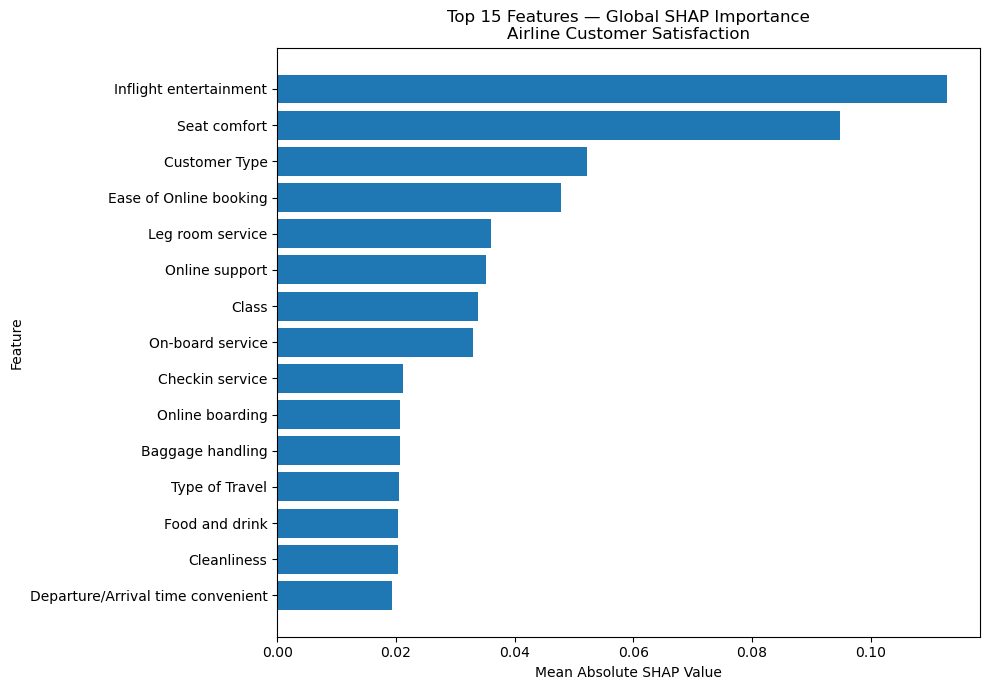

In [122]:
# ============================================================
# TOP 15 GLOBAL SHAP FEATURES
# ============================================================

import matplotlib.pyplot as plt

top_15_shap = (
    shap_importance_1000
    .head(15)
    .sort_values('Mean Absolute SHAP')
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_15_shap['Feature'],
    top_15_shap['Mean Absolute SHAP']
)

plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title(
    'Top 15 Features — Global SHAP Importance\n'
    'Airline Customer Satisfaction'
)

plt.tight_layout()
plt.show()

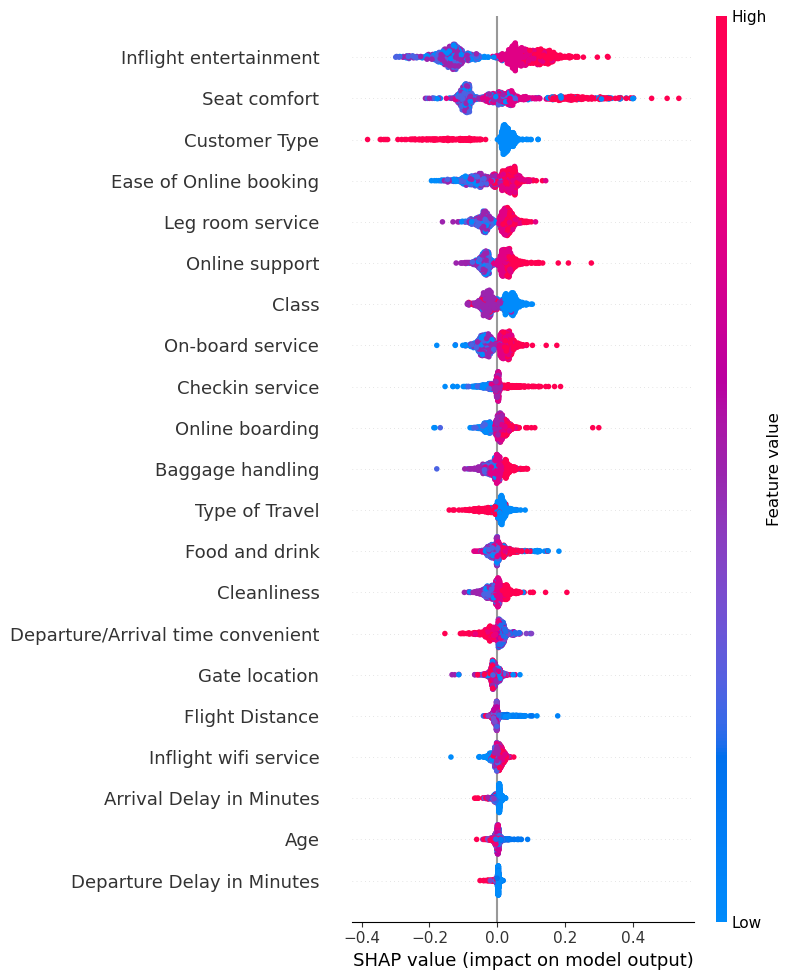

In [123]:
# ============================================================
# SHAP BEESWARM PLOT — 1,000 PASSENGERS
# ============================================================

shap.summary_plot(
    shap_satisfied_1000,
    X_shap_1000_processed,
    feature_names=feature_names,
    max_display=21,
    show=True
)

In [124]:
# ============================================================
# TEXT-BASED SHAP EXPLANATION
# 1,000 PASSENGER SAMPLE
# ============================================================

# Create a summary dataframe
shap_text_report = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP': np.abs(
        shap_satisfied_1000
    ).mean(axis=0),
    'Mean SHAP': shap_satisfied_1000.mean(axis=0),
    'Positive %': (
        (shap_satisfied_1000 > 0).mean(axis=0) * 100
    ),
    'Negative %': (
        (shap_satisfied_1000 < 0).mean(axis=0) * 100
    )
})

# Sort by importance
shap_text_report = shap_text_report.sort_values(
    'Mean Absolute SHAP',
    ascending=False
).reset_index(drop=True)

# Display rounded results
display(
    shap_text_report.round({
        'Mean Absolute SHAP': 4,
        'Mean SHAP': 4,
        'Positive %': 1,
        'Negative %': 1
    })
)

,Feature,Mean Absolute SHAP,Mean SHAP,Positive %,Negative %
0,Inflight entertainment,0.1128,-0.0076,55.8,44.2
1,Seat comfort,0.0949,0.0142,47.6,52.4
2,Customer Type,0.0522,-0.0038,81.0,19.0
3,Ease of Online booking,0.0478,-0.0071,53.4,46.6
4,Leg room service,0.0361,-0.0002,57.6,42.4
5,Online support,0.0351,0.0031,58.3,41.7
6,Class,0.0339,0.0028,49.2,50.8
7,On-board service,0.0330,-0.0025,53.5,46.5
8,Checkin service,0.0212,0.0006,49.3,50.7
9,Online boarding,0.0208,0.0036,65.7,34.3


In [125]:
# ============================================================
# HUMAN-READABLE SHAP REPORT
# ============================================================

print("=" * 85)
print("AIRLINE CUSTOMER SATISFACTION — SHAP EXPLAINABILITY REPORT")
print("Based on 1,000 representative test passengers")
print("=" * 85)

for i, row in shap_text_report.iterrows():

    feature = row['Feature']
    importance = row['Mean Absolute SHAP']
    mean_shap = row['Mean SHAP']
    positive = row['Positive %']
    negative = row['Negative %']

    print(f"\n{i + 1}. {feature}")
    print(f"   Mean Absolute SHAP : {importance:.4f}")
    print(f"   Mean SHAP          : {mean_shap:.4f}")
    print(f"   Positive           : {positive:.1f}%")
    print(f"   Negative           : {negative:.1f}%")

AIRLINE CUSTOMER SATISFACTION — SHAP EXPLAINABILITY REPORT
Based on 1,000 representative test passengers

1. Inflight entertainment
   Mean Absolute SHAP : 0.1128
   Mean SHAP          : -0.0076
   Positive           : 55.8%
   Negative           : 44.2%

2. Seat comfort
   Mean Absolute SHAP : 0.0949
   Mean SHAP          : 0.0142
   Positive           : 47.6%
   Negative           : 52.4%

3. Customer Type
   Mean Absolute SHAP : 0.0522
   Mean SHAP          : -0.0038
   Positive           : 81.0%
   Negative           : 19.0%

4. Ease of Online booking
   Mean Absolute SHAP : 0.0478
   Mean SHAP          : -0.0071
   Positive           : 53.4%
   Negative           : 46.6%

5. Leg room service
   Mean Absolute SHAP : 0.0361
   Mean SHAP          : -0.0002
   Positive           : 57.6%
   Negative           : 42.4%

6. Online support
   Mean Absolute SHAP : 0.0351
   Mean SHAP          : 0.0031
   Positive           : 58.3%
   Negative           : 41.7%

7. Class
   Mean Absolute SHA

In [126]:
# ============================================================
# TOP 10 SHAP FEATURES — TEXT SUMMARY
# ============================================================

print("=" * 75)
print("TOP 10 SATISFACTION PREDICTORS")
print("=" * 75)

top_10 = shap_text_report.head(10)

for rank, (_, row) in enumerate(top_10.iterrows(), start=1):

    print(
        f"{rank:2}. "
        f"{row['Feature']:<40} "
        f"SHAP = {row['Mean Absolute SHAP']:.4f}"
    )

TOP 10 SATISFACTION PREDICTORS
 1. Inflight entertainment                   SHAP = 0.1128
 2. Seat comfort                             SHAP = 0.0949
 3. Customer Type                            SHAP = 0.0522
 4. Ease of Online booking                   SHAP = 0.0478
 5. Leg room service                         SHAP = 0.0361
 6. Online support                           SHAP = 0.0351
 7. Class                                    SHAP = 0.0339
 8. On-board service                         SHAP = 0.0330
 9. Checkin service                          SHAP = 0.0212
10. Online boarding                          SHAP = 0.0208


In [127]:
# ============================================================
# SHAP DIRECTIONAL ANALYSIS
# ============================================================

print("=" * 85)
print("SHAP DIRECTIONAL ANALYSIS")
print("=" * 85)

for _, row in shap_text_report.iterrows():

    feature = row['Feature']
    mean_shap = row['Mean SHAP']
    positive = row['Positive %']
    negative = row['Negative %']

    if positive >= 70:
        pattern = "Mostly positive"
    elif negative >= 70:
        pattern = "Mostly negative"
    else:
        pattern = "Mixed / context-dependent"

    print(
        f"{feature:<40} | "
        f"Mean SHAP: {mean_shap:+.4f} | "
        f"Positive: {positive:5.1f}% | "
        f"Negative: {negative:5.1f}% | "
        f"{pattern}"
    )

SHAP DIRECTIONAL ANALYSIS
Inflight entertainment                   | Mean SHAP: -0.0076 | Positive:  55.8% | Negative:  44.2% | Mixed / context-dependent
Seat comfort                             | Mean SHAP: +0.0142 | Positive:  47.6% | Negative:  52.4% | Mixed / context-dependent
Customer Type                            | Mean SHAP: -0.0038 | Positive:  81.0% | Negative:  19.0% | Mostly positive
Ease of Online booking                   | Mean SHAP: -0.0071 | Positive:  53.4% | Negative:  46.6% | Mixed / context-dependent
Leg room service                         | Mean SHAP: -0.0002 | Positive:  57.6% | Negative:  42.4% | Mixed / context-dependent
Online support                           | Mean SHAP: +0.0031 | Positive:  58.3% | Negative:  41.7% | Mixed / context-dependent
Class                                    | Mean SHAP: +0.0028 | Positive:  49.2% | Negative:  50.8% | Mixed / context-dependent
On-board service                         | Mean SHAP: -0.0025 | Positive:  53.5% | Negat

In [128]:
# ============================================================
# ORIGINAL VALUES FOR THE 1,000 SHAP PASSENGERS
# ============================================================

X_shap_1000_raw = X_shap_1000.copy()

print("Raw SHAP sample shape:", X_shap_1000_raw.shape)

# ============================================================
# VALUE-LEVEL SHAP ANALYSIS
# ============================================================

rating_features = [
    'Inflight entertainment',
    'Seat comfort',
    'Ease of Online booking',
    'Leg room service',
    'Online support',
    'On-board service',
    'Food and drink',
    'Online boarding'
]

for feature in rating_features:

    print("\n" + "=" * 75)
    print(feature)
    print("=" * 75)

    feature_index = feature_names.index(feature)

    temp = pd.DataFrame({
        'Value': X_shap_1000_raw[feature].values,
        'SHAP': shap_satisfied_1000[:, feature_index]
    })

    summary = (
        temp
        .groupby('Value')['SHAP']
        .agg(['mean', 'count'])
        .reset_index()
    )

    summary.columns = [
        'Rating',
        'Mean SHAP',
        'Passengers'
    ]

    print(summary.round(4).to_string(index=False))

Raw SHAP sample shape: (1000, 21)

Inflight entertainment
 Rating  Mean SHAP  Passengers
      0    -0.0599          17
      1    -0.1270          89
      2    -0.1389         157
      3    -0.1433         181
      4     0.0650         345
      5     0.1424         211

Seat comfort
 Rating  Mean SHAP  Passengers
      0     0.2551          33
      1    -0.0452         152
      2    -0.0682         232
      3    -0.0708         198
      4     0.0334         242
      5     0.2410         143

Ease of Online booking
 Rating  Mean SHAP  Passengers
      0    -0.0924           1
      1    -0.0945         107
      2    -0.0571         144
      3    -0.0479         172
      4     0.0366         321
      5     0.0305         255

Leg room service
 Rating  Mean SHAP  Passengers
      0    -0.0600           1
      1    -0.0451          98
      2    -0.0392         175
      3    -0.0454         147
      4     0.0248         309
      5     0.0377         270

Online support
 R

In [129]:
from pathlib import Path

# Create directories for saved ML artifacts
Path("models").mkdir(exist_ok=True)
Path("models/shap").mkdir(parents=True, exist_ok=True)

print("Model directories created successfully.")

Model directories created successfully.


In [130]:
import joblib

model_path = "models/airline_satisfaction_rf_pipeline.joblib"

joblib.dump(
    random_forest_model,
    model_path
)

print(f"Model saved successfully: {model_path}")

random_forest_model.named_steps["classifier"]

Model saved successfully: models/airline_satisfaction_rf_pipeline.joblib


,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [131]:
# Load the saved model
loaded_model = joblib.load(
    "models/airline_satisfaction_rf_pipeline.joblib"
)

# Test prediction on a few existing passengers
test_predictions = loaded_model.predict(X_test.head(5))

print("Test predictions:", test_predictions)

original_predictions = random_forest_model.predict(X_test.head(5))

print("Original predictions:", original_predictions)
print("Loaded predictions:  ", test_predictions)

print(
    "Predictions identical:",
    (original_predictions == test_predictions).all()
)

Test predictions: [1 0 0 1 0]
Original predictions: [1 0 0 1 0]
Loaded predictions:   [1 0 0 1 0]
Predictions identical: True


In [132]:
import json

metadata = {
    "project": "Airline Customer Satisfaction Prediction",
    "model": {
        "name": "Random Forest Classifier",
        "pipeline": "Median Imputation + StandardScaler + Random Forest",
        "selection_status": "Final selected model candidate",
        "random_state": 42
    },

    "target": {
        "name": "satisfaction",
        "classes": {
            "0": "Neutral/Dissatisfied",
            "1": "Satisfied"
        }
    },

    "features": list(X.columns),

    "categorical_mappings": {
        "Customer Type": {
            "0": "Loyal Customer",
            "1": "Disloyal Customer"
        },
        "Type of Travel": {
            "0": "Business travel",
            "1": "Personal Travel"
        },
        "Class": {
            "0": "Business",
            "1": "Eco",
            "2": "Eco Plus"
        }
    },

    "evaluation": {
        "test_accuracy": 0.956075,
        "test_precision": 0.969347,
        "test_recall": 0.949778,
        "test_f1": 0.959463,
        "test_roc_auc": 0.992843,

        "cv_accuracy_mean": 0.9547,
        "cv_accuracy_std": 0.0008,

        "cv_precision_mean": 0.9672,
        "cv_precision_std": 0.0015,

        "cv_recall_mean": 0.9494,
        "cv_recall_std": 0.0018,

        "cv_f1_mean": 0.9582,
        "cv_f1_std": 0.0008,

        "cv_roc_auc_mean": 0.9925,
        "cv_roc_auc_std": 0.0002
    }
}

metadata_path = "models/model_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print(f"Metadata saved successfully: {metadata_path}")

Metadata saved successfully: models/model_metadata.json


In [134]:
shap_sample_path = "models/shap/shap_background_sample.joblib"

joblib.dump(
    X_shap_1000,
    shap_sample_path
)

print(f"SHAP sample saved successfully: {shap_sample_path}")

shap_explainer_path = "models/shap/tree_explainer.joblib"

joblib.dump(
    explainer,
    shap_explainer_path
)

print(f"SHAP explainer saved successfully: {shap_explainer_path}")

SHAP sample saved successfully: models/shap/shap_background_sample.joblib
SHAP explainer saved successfully: models/shap/tree_explainer.joblib


In [135]:
from pathlib import Path

for path in Path("models").rglob("*"):
    if path.is_file():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"{path} — {size_mb:.2f} MB")

models\airline_satisfaction_rf_pipeline.joblib — 199.49 MB
models\model_metadata.json — 0.00 MB
models\shap\shap_background_sample.joblib — 0.17 MB
models\shap\tree_explainer.joblib — 275.34 MB


In [136]:
from pathlib import Path

explainer_path = Path("models/shap/tree_explainer.joblib")

if explainer_path.exists():
    explainer_path.unlink()
    print("Saved SHAP explainer deleted successfully.")
else:
    print("SHAP explainer file not found.")

Saved SHAP explainer deleted successfully.


In [137]:
for path in Path("models").rglob("*"):
    if path.is_file():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"{path} — {size_mb:.2f} MB")


from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import joblib
import os
import time

tree_counts = [50, 75, 100, 150, 200]

size_experiment = []

for n_trees in tree_counts:

    print(f"\nTraining Random Forest with {n_trees} trees...")

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=n_trees,
            random_state=42,
            n_jobs=-1
        ))
    ])

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score
    )

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)
    roc_auc = roc_auc_score(y_test, probabilities)

    temp_path = f"models/rf_{n_trees}_trees.joblib"

    joblib.dump(model, temp_path)

    size_mb = os.path.getsize(temp_path) / (1024 * 1024)

    size_experiment.append({
        "n_trees": n_trees,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "training_time_seconds": training_time,
        "size_mb": size_mb
    })

    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1:       {f1:.4f}")
    print(f"ROC-AUC:  {roc_auc:.4f}")
    print(f"Size:     {size_mb:.2f} MB")

models\airline_satisfaction_rf_pipeline.joblib — 199.49 MB
models\model_metadata.json — 0.00 MB
models\shap\shap_background_sample.joblib — 0.17 MB

Training Random Forest with 50 trees...
Accuracy: 0.9548
F1:       0.9582
ROC-AUC:  0.9924
Size:     49.71 MB

Training Random Forest with 75 trees...
Accuracy: 0.9554
F1:       0.9589
ROC-AUC:  0.9926
Size:     74.73 MB

Training Random Forest with 100 trees...
Accuracy: 0.9557
F1:       0.9591
ROC-AUC:  0.9927
Size:     99.57 MB

Training Random Forest with 150 trees...
Accuracy: 0.9560
F1:       0.9594
ROC-AUC:  0.9928
Size:     149.54 MB

Training Random Forest with 200 trees...
Accuracy: 0.9561
F1:       0.9595
ROC-AUC:  0.9928
Size:     199.49 MB


In [138]:
import pandas as pd

size_experiment_df = pd.DataFrame(size_experiment)

size_experiment_df

,n_trees,accuracy,precision,recall,f1,roc_auc,training_time_seconds,size_mb
0,50,0.954766,0.969069,0.947598,0.958213,0.992399,7.285532,49.713115
1,75,0.955420,0.967763,0.950200,0.958901,0.992631,10.863445,74.730128
2,100,0.955690,0.968719,0.949708,0.959119,0.992708,13.377022,99.572581
3,150,0.955998,0.969882,0.949075,0.959366,0.992780,21.096991,149.537181
4,200,0.956075,0.969347,0.949778,0.959463,0.992843,25.417205,199.492473


In [139]:
import joblib

deployment_model = joblib.load(
    "models/rf_100_trees.joblib"
)

print(deployment_model)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

deployment_pred = deployment_model.predict(X_test)
deployment_prob = deployment_model.predict_proba(X_test)[:, 1]

print("Deployment Candidate Metrics")
print("-" * 40)
print(f"Accuracy : {accuracy_score(y_test, deployment_pred):.6f}")
print(f"Precision: {precision_score(y_test, deployment_pred):.6f}")
print(f"Recall   : {recall_score(y_test, deployment_pred):.6f}")
print(f"F1 Score : {f1_score(y_test, deployment_pred):.6f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, deployment_prob):.6f}")

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])
Deployment Candidate Metrics
----------------------------------------
Accuracy : 0.955690
Precision: 0.968719
Recall   : 0.949708
F1 Score : 0.959119
ROC-AUC  : 0.992708


In [142]:
import joblib

final_model_path = "models/airline_satisfaction_rf_pipeline.joblib"

joblib.dump(
    deployment_model,
    final_model_path
)

print(f"Final deployment model saved to:")
print(final_model_path)

from pathlib import Path

model_file = Path(
    "models/airline_satisfaction_rf_pipeline.joblib"
)

size_mb = model_file.stat().st_size / (1024 * 1024)

print(f"Final model size: {size_mb:.2f} MB")

from pathlib import Path

for n in [50, 75, 100, 150, 200]:
    temp_file = Path(f"models/rf_{n}_trees.joblib")

    if temp_file.exists():
        temp_file.unlink()

print("Temporary Random Forest experiment files removed.")

Final deployment model saved to:
models/airline_satisfaction_rf_pipeline.joblib
Final model size: 99.57 MB
Temporary Random Forest experiment files removed.


In [143]:
metadata["model"]["n_estimators"] = 100
metadata["model"]["selection_reason"] = (
    "Selected for deployment because it provides nearly identical "
    "predictive performance to the 200-tree model while reducing "
    "model size by approximately 50%."
)

with open("models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model metadata updated successfully.")

Model metadata updated successfully.


In [145]:
## Validate the 100-tree model with 5-fold CV
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-fold stratified cross-validation
cv_100 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results_100 = cross_validate(
    deployment_model,
    X_train,
    y_train,
    cv=cv_100,
    scoring=[
        'accuracy',
        'precision',
        'recall',
        'f1',
        'roc_auc'
    ],
    n_jobs=-1
)

##summarize the results:

import pandas as pd

cv_summary_100 = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        cv_results_100["test_accuracy"].mean(),
        cv_results_100["test_precision"].mean(),
        cv_results_100["test_recall"].mean(),
        cv_results_100["test_f1"].mean(),
        cv_results_100["test_roc_auc"].mean()
    ],
    "Std": [
        cv_results_100["test_accuracy"].std(),
        cv_results_100["test_precision"].std(),
        cv_results_100["test_recall"].std(),
        cv_results_100["test_f1"].std(),
        cv_results_100["test_roc_auc"].std()
    ]
})

cv_summary_100

,Metric,Mean,Std
0,Accuracy,0.954429,0.000945
1,Precision,0.967324,0.001847
2,Recall,0.948795,0.001489
3,F1,0.957968,0.000857
4,ROC-AUC,0.992308,0.000221


In [147]:
## save the deployment model again:

import joblib

final_model_path = "models/airline_satisfaction_rf_pipeline.joblib"

joblib.dump(
    deployment_model,
    final_model_path
)

print("Final deployment model saved.")



## Now simulate what Streamlit will do:
# Reload exactly as the future application will
production_candidate = joblib.load(
    "models/airline_satisfaction_rf_pipeline.joblib"
)

print("Model loaded successfully.")
print(production_candidate)



## Now compare predictions:
# Predictions from original in-memory model
original_pred = deployment_model.predict(X_test.head(100))

# Predictions from saved/reloaded model
loaded_pred = production_candidate.predict(X_test.head(100))

print(
    "Predictions identical:",
    (original_pred == loaded_pred).all()
)

## Test probabilities:
original_prob = deployment_model.predict_proba(
    X_test.head(100)
)[:, 1]

loaded_prob = production_candidate.predict_proba(
    X_test.head(100)
)[:, 1]

print(
    "Probabilities identical:",
    (abs(original_prob - loaded_prob) < 1e-12).all()
)

Final deployment model saved.
Model loaded successfully.
Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('classifier',
                 RandomForestClassifier(n_jobs=-1, random_state=42))])
Predictions identical: True
Probabilities identical: True


In [148]:
## Finalize the metadata
import json

metadata = {
    "project": "Airline Customer Satisfaction Prediction",

    "model": {
        "name": "Random Forest Classifier",
        "n_estimators": 100,
        "random_state": 42,
        "pipeline": [
            "Median imputation",
            "StandardScaler",
            "Random Forest"
        ],
        "selection_status": "Final deployment candidate",
        "selection_reason": (
            "The 100-tree model provides nearly identical predictive "
            "performance to the 200-tree benchmark while reducing "
            "model size by approximately 50%."
        )
    },

    "target": {
        "name": "satisfaction",
        "classes": {
            "0": "Neutral/Dissatisfied",
            "1": "Satisfied"
        }
    },

    "features": list(X.columns),

    "categorical_mappings": {
        "Customer Type": {
            "0": "Loyal Customer",
            "1": "Disloyal Customer"
        },

        "Type of Travel": {
            "0": "Business travel",
            "1": "Personal Travel"
        },

        "Class": {
            "0": "Business",
            "1": "Eco",
            "2": "Eco Plus"
        }
    },

    "test_metrics": {
        "accuracy": float(
            accuracy_score(y_test, deployment_pred)
        ),
        "precision": float(
            precision_score(y_test, deployment_pred)
        ),
        "recall": float(
            recall_score(y_test, deployment_pred)
        ),
        "f1": float(
            f1_score(y_test, deployment_pred)
        ),
        "roc_auc": float(
            roc_auc_score(y_test, deployment_prob)
        )
    },

    "cross_validation": {
        "folds": 5,
        "accuracy_mean": float(
            cv_results_100["test_accuracy"].mean()
        ),
        "accuracy_std": float(
            cv_results_100["test_accuracy"].std()
        ),
        "precision_mean": float(
            cv_results_100["test_precision"].mean()
        ),
        "precision_std": float(
            cv_results_100["test_precision"].std()
        ),
        "recall_mean": float(
            cv_results_100["test_recall"].mean()
        ),
        "recall_std": float(
            cv_results_100["test_recall"].std()
        ),
        "f1_mean": float(
            cv_results_100["test_f1"].mean()
        ),
        "f1_std": float(
            cv_results_100["test_f1"].std()
        ),
        "roc_auc_mean": float(
            cv_results_100["test_roc_auc"].mean()
        ),
        "roc_auc_std": float(
            cv_results_100["test_roc_auc"].std()
        )
    },

    "explainability": {
        "method": "SHAP",
        "explainer": "TreeExplainer",
        "background_sample_size": 1000
    }
}

with open(
    "models/model_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("Final metadata saved successfully.")

Final metadata saved successfully.


In [149]:
## Clean up temporary models
from pathlib import Path

for n in [50, 75, 100, 150, 200]:

    temp_file = Path(
        f"models/rf_{n}_trees.joblib"
    )

    if temp_file.exists():
        temp_file.unlink()

print("Temporary model files removed.")



## Then check:
for path in Path("models").rglob("*"):

    if path.is_file():

        size_mb = path.stat().st_size / (1024 * 1024)

        print(
            f"{path} — {size_mb:.2f} MB"
        )

Temporary model files removed.
models\airline_satisfaction_rf_pipeline.joblib — 99.57 MB
models\model_metadata.json — 0.00 MB
models\shap\shap_background_sample.joblib — 0.17 MB


In [150]:
## Create the src folder:

from pathlib import Path

Path("src").mkdir(exist_ok=True)

Path("src/__init__.py").touch()

print("src package created.")

src package created.


In [151]:
## Create predict.py
from pathlib import Path

predict_code = '''
from pathlib import Path
import json
import joblib
import pandas as pd


# ---------------------------------------------------------
# Paths
# ---------------------------------------------------------

BASE_DIR = Path(__file__).resolve().parent.parent

MODEL_PATH = (
    BASE_DIR
    / "models"
    / "airline_satisfaction_rf_pipeline.joblib"
)

METADATA_PATH = (
    BASE_DIR
    / "models"
    / "model_metadata.json"
)


# ---------------------------------------------------------
# Load model and metadata
# ---------------------------------------------------------

model = joblib.load(MODEL_PATH)

with open(METADATA_PATH, "r") as f:
    metadata = json.load(f)


# ---------------------------------------------------------
# Prediction function
# ---------------------------------------------------------

def predict_satisfaction(passenger_data):
    """
    Predict airline passenger satisfaction.

    Parameters
    ----------
    passenger_data : pandas.DataFrame
        DataFrame containing the 21 model features.

    Returns
    -------
    dict
        Prediction, probabilities and confidence.
    """

    if not isinstance(passenger_data, pd.DataFrame):
        passenger_data = pd.DataFrame(passenger_data)

    probabilities = model.predict_proba(passenger_data)[0]

    prediction = int(model.predict(passenger_data)[0])

    satisfied_probability = float(probabilities[1])
    dissatisfied_probability = float(probabilities[0])

    if prediction == 1:
        label = "Satisfied"
    else:
        label = "Neutral/Dissatisfied"

    confidence = max(
        satisfied_probability,
        dissatisfied_probability
    )

    return {
        "prediction": prediction,
        "label": label,
        "satisfied_probability": satisfied_probability,
        "dissatisfied_probability": dissatisfied_probability,
        "confidence": float(confidence)
    }


# ---------------------------------------------------------
# Feature validation
# ---------------------------------------------------------

def validate_features(passenger_data):
    """
    Validate that all required model features are present.
    """

    if not isinstance(passenger_data, pd.DataFrame):
        passenger_data = pd.DataFrame(passenger_data)

    required_features = metadata["features"]

    missing_features = [
        feature
        for feature in required_features
        if feature not in passenger_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    return True
'''

Path("src/predict.py").write_text(
    predict_code,
    encoding="utf-8"
)
print("src/predict.py created successfully.")


## Test the inference layer
import sys
if "src" not in sys.path:
    sys.path.append(".")

from src.predict import (
    predict_satisfaction,
    validate_features
)



## Take one passenger:
sample_passenger = X_test.iloc[[0]].copy()
sample_passenger



##Validate:
validate_features(sample_passenger)
print("Feature validation passed.")


## Then predict:
result = predict_satisfaction(
    sample_passenger
)

result

src/predict.py created successfully.
Feature validation passed.


{'prediction': 1,
 'label': 'Satisfied',
 'satisfied_probability': 0.93,
 'dissatisfied_probability': 0.07,
 'confidence': 0.93}

In [153]:
## Create src/explain.py
from pathlib import Path
explain_code = '''
from pathlib import Path
import joblib
import json
import pandas as pd
import numpy as np
import shap


# =========================================================
# Paths
# =========================================================

BASE_DIR = Path(__file__).resolve().parent.parent

MODEL_PATH = (
    BASE_DIR
    / "models"
    / "airline_satisfaction_rf_pipeline.joblib"
)

METADATA_PATH = (
    BASE_DIR
    / "models"
    / "model_metadata.json"
)


# =========================================================
# Load model and metadata
# =========================================================

model = joblib.load(MODEL_PATH)

with open(METADATA_PATH, "r") as f:
    metadata = json.load(f)


# =========================================================
# Extract fitted components
# =========================================================

preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]


# =========================================================
# Create SHAP explainer
# =========================================================

explainer = shap.TreeExplainer(classifier)


# =========================================================
# Categorical display mappings
# =========================================================

CATEGORY_MAPPINGS = {
    "Customer Type": {
        0: "Loyal Customer",
        1: "Disloyal Customer"
    },

    "Type of Travel": {
        0: "Business travel",
        1: "Personal Travel"
    },

    "Class": {
        0: "Business",
        1: "Eco",
        2: "Eco Plus"
    }
}


# =========================================================
# Human-readable value formatter
# =========================================================

def format_feature_value(feature, value):
    """
    Convert encoded categorical values into human-readable labels.
    """

    if feature in CATEGORY_MAPPINGS:

        try:
            value = int(value)
            return CATEGORY_MAPPINGS[feature].get(
                value,
                str(value)
            )

        except (ValueError, TypeError):
            return str(value)

    return str(value)


# =========================================================
# SHAP value extraction
# =========================================================

def get_satisfied_shap_values(processed_data):
    """
    Extract SHAP values associated with the Satisfied class.
    Handles different SHAP output formats.
    """

    shap_values = explainer.shap_values(
        processed_data
    )

    # Older SHAP versions may return:
    # [class_0_values, class_1_values]

    if isinstance(shap_values, list):
        return np.asarray(shap_values[1])

    shap_values = np.asarray(shap_values)

    # Newer SHAP versions may return:
    # samples x features x classes

    if shap_values.ndim == 3:
        return shap_values[:, :, 1]

    # Binary/single-output format

    return shap_values


# =========================================================
# Explain one passenger
# =========================================================

def explain_passenger(passenger_data):
    """
    Generate a local SHAP explanation for one passenger.

    Returns:
        dict containing prediction, probabilities,
        and ranked positive/negative SHAP factors.
    """

    if not isinstance(passenger_data, pd.DataFrame):
        passenger_data = pd.DataFrame(passenger_data)

    required_features = metadata["features"]

    missing_features = [
        feature
        for feature in required_features
        if feature not in passenger_data.columns
    ]

    if missing_features:
        raise ValueError(
            f"Missing required features: {missing_features}"
        )

    # Keep features in the exact training order
    passenger_data = passenger_data[
        required_features
    ].copy()

    # Transform using the fitted preprocessing pipeline
    processed_data = preprocessor.transform(
        passenger_data
    )

    # Generate SHAP values
    shap_values = get_satisfied_shap_values(
        processed_data
    )

    # Prediction
    probabilities = model.predict_proba(
        passenger_data
    )[0]

    prediction = int(
        model.predict(passenger_data)[0]
    )

    satisfied_probability = float(
        probabilities[1]
    )

    dissatisfied_probability = float(
        probabilities[0]
    )

    confidence = max(
        satisfied_probability,
        dissatisfied_probability
    )

    label = (
        "Satisfied"
        if prediction == 1
        else "Neutral/Dissatisfied"
    )

    # Feature-level explanation
    explanations = []

    for i, feature in enumerate(required_features):

        shap_value = float(
            shap_values[0, i]
        )

        raw_value = passenger_data.iloc[0][feature]

        explanations.append({
            "feature": feature,
            "value": raw_value,
            "display_value": format_feature_value(
                feature,
                raw_value
            ),
            "shap_value": shap_value
        })

    # Rank by contribution
    positive_factors = sorted(
        [
            item
            for item in explanations
            if item["shap_value"] > 0
        ],
        key=lambda x: x["shap_value"],
        reverse=True
    )

    negative_factors = sorted(
        [
            item
            for item in explanations
            if item["shap_value"] < 0
        ],
        key=lambda x: x["shap_value"]
    )

    return {
        "prediction": prediction,
        "label": label,
        "satisfied_probability": satisfied_probability,
        "dissatisfied_probability": dissatisfied_probability,
        "confidence": float(confidence),
        "positive_factors": positive_factors,
        "negative_factors": negative_factors,
        "all_factors": explanations
    }
'''

Path("src/explain.py").write_text(
    explain_code,
    encoding="utf-8"
)

print("src/explain.py created successfully.")


## Test SHAP on our passenger
from src.explain import explain_passenger

## Use the same passenger we tested previously:
sample_passenger = X_test.iloc[[0]].copy()
explanation = explain_passenger(sample_passenger)

## Inspect the prediction:
print("Prediction:", explanation["label"])
print(
    "Satisfied probability:",
    f"{explanation['satisfied_probability']:.2%}"
)
print(
    "Dissatisfied probability:",
    f"{explanation['dissatisfied_probability']:.2%}"
)
print(
    "Confidence:",
    f"{explanation['confidence']:.2%}"
)

src/explain.py created successfully.
Prediction: Satisfied
Satisfied probability: 93.00%
Dissatisfied probability: 7.00%
Confidence: 93.00%


In [154]:
## Display the strongest positive factors
for item in explanation["positive_factors"][:5]:

    print(
        f"+ {item['feature']}: "
        f"{item['display_value']} "
        f"→ SHAP {item['shap_value']:+.4f}")

## Display the strongest negative factors
for item in explanation["negative_factors"][:5]:

    print(
        f"- {item['feature']}: "
        f"{item['display_value']} "
        f"→ SHAP {item['shap_value']:+.4f}")

+ Seat comfort: 0.0 → SHAP +0.3149
+ Food and drink: 0.0 → SHAP +0.1360
+ Class: Business → SHAP +0.0369
+ Customer Type: Loyal Customer → SHAP +0.0223
+ Departure/Arrival time convenient: 0.0 → SHAP +0.0127
- Inflight entertainment: 3.0 → SHAP -0.0924
- Ease of Online booking: 3.0 → SHAP -0.0428
- Online support: 3.0 → SHAP -0.0382
- Checkin service: 3.0 → SHAP -0.0050
- Baggage handling: 4.0 → SHAP -0.0039


In [155]:
## Create a clean explanation table

explanation_table = pd.DataFrame(
    explanation["all_factors"]
)

explanation_table["abs_shap"] = (
    explanation_table["shap_value"].abs()
)

explanation_table = explanation_table.sort_values(
    "abs_shap",
    ascending=False
)

explanation_table[
    [
        "feature",
        "display_value",
        "shap_value"
    ]
].head(10)

,feature,display_value,shap_value
5,Seat comfort,0.0,0.314882
7,Food and drink,0.0,0.135977
10,Inflight entertainment,3.0,-0.092360
12,Ease of Online booking,3.0,-0.042768
11,Online support,3.0,-0.038155
3,Class,Business,0.036899
0,Customer Type,Loyal Customer,0.022343
6,Departure/Arrival time convenient,0.0,0.012711
20,Arrival Delay in Minutes,0.0,0.012075
14,Leg room service,4.0,0.008893


In [157]:
## Create src/config.py
from pathlib import Path
config_code = '''
# =========================================================
# Airline Satisfaction AI — Application Configuration
# =========================================================

# ---------------------------------------------------------
# Model features
# ---------------------------------------------------------

FEATURES = [
    "Customer Type",
    "Age",
    "Type of Travel",
    "Class",
    "Flight Distance",
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
    "Online boarding",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]


# ---------------------------------------------------------
# Categorical features
# ---------------------------------------------------------

CATEGORICAL_FEATURES = [
    "Customer Type",
    "Type of Travel",
    "Class"
]


# ---------------------------------------------------------
# Categorical options
# ---------------------------------------------------------

CUSTOMER_TYPES = {
    "Loyal Customer": 0,
    "Disloyal Customer": 1
}

TRAVEL_TYPES = {
    "Business travel": 0,
    "Personal Travel": 1
}

CLASS_TYPES = {
    "Business": 0,
    "Eco": 1,
    "Eco Plus": 2
}


# ---------------------------------------------------------
# Rating-based features
# ---------------------------------------------------------

RATING_FEATURES = [
    "Seat comfort",
    "Departure/Arrival time convenient",
    "Food and drink",
    "Gate location",
    "Inflight wifi service",
    "Inflight entertainment",
    "Online support",
    "Ease of Online booking",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
    "Online boarding"
]


# ---------------------------------------------------------
# Rating limits
# ---------------------------------------------------------

RATING_MIN = 0
RATING_MAX = 5


# ---------------------------------------------------------
# Target labels
# ---------------------------------------------------------

TARGET_LABELS = {
    0: "Neutral/Dissatisfied",
    1: "Satisfied"
}


# ---------------------------------------------------------
# Human-readable feature names
# ---------------------------------------------------------

DISPLAY_NAMES = {
    "Customer Type": "Customer type",
    "Age": "Age",
    "Type of Travel": "Travel type",
    "Class": "Travel class",
    "Flight Distance": "Flight distance",
    "Seat comfort": "Seat comfort",
    "Departure/Arrival time convenient": "Departure/arrival convenience",
    "Food and drink": "Food & drink",
    "Gate location": "Gate location",
    "Inflight wifi service": "Inflight Wi-Fi",
    "Inflight entertainment": "Inflight entertainment",
    "Online support": "Online support",
    "Ease of Online booking": "Ease of online booking",
    "On-board service": "On-board service",
    "Leg room service": "Leg room",
    "Baggage handling": "Baggage handling",
    "Checkin service": "Check-in service",
    "Cleanliness": "Cleanliness",
    "Online boarding": "Online boarding",
    "Departure Delay in Minutes": "Departure delay",
    "Arrival Delay in Minutes": "Arrival delay"
}


# ---------------------------------------------------------
# Feature descriptions
# ---------------------------------------------------------

FEATURE_DESCRIPTIONS = {
    "Seat comfort":
        "Passenger rating of seat comfort.",

    "Departure/Arrival time convenient":
        "Passenger rating of departure and arrival time convenience.",

    "Food and drink":
        "Passenger rating of food and beverage service.",

    "Gate location":
        "Passenger rating of gate location.",

    "Inflight wifi service":
        "Passenger rating of inflight Wi-Fi service.",

    "Inflight entertainment":
        "Passenger rating of inflight entertainment.",

    "Online support":
        "Passenger rating of online customer support.",

    "Ease of Online booking":
        "Passenger rating of online booking convenience.",

    "On-board service":
        "Passenger rating of onboard service.",

    "Leg room service":
        "Passenger rating of available leg room.",

    "Baggage handling":
        "Passenger rating of baggage handling.",

    "Checkin service":
        "Passenger rating of check-in service.",

    "Cleanliness":
        "Passenger rating of cabin cleanliness.",

    "Online boarding":
        "Passenger rating of online boarding."
}


# ---------------------------------------------------------
# Business-friendly SHAP explanations
# ---------------------------------------------------------

SHAP_EXPLANATION_NAMES = {
    "Inflight entertainment":
        "Inflight entertainment",

    "Seat comfort":
        "Seat comfort",

    "Customer Type":
        "Customer loyalty",

    "Ease of Online booking":
        "Online booking experience",

    "Leg room service":
        "Leg room",

    "Online support":
        "Online support",

    "Class":
        "Travel class",

    "On-board service":
        "Onboard service",

    "Checkin service":
        "Check-in experience",

    "Online boarding":
        "Online boarding",

    "Baggage handling":
        "Baggage handling",

    "Type of Travel":
        "Travel purpose",

    "Food and drink":
        "Food & drink",

    "Cleanliness":
        "Cabin cleanliness",

    "Departure/Arrival time convenient":
        "Schedule convenience",

    "Gate location":
        "Gate location",

    "Flight Distance":
        "Flight distance",

    "Inflight wifi service":
        "Inflight Wi-Fi",

    "Arrival Delay in Minutes":
        "Arrival delay",

    "Age":
        "Passenger age",

    "Departure Delay in Minutes":
        "Departure delay"
}


# ---------------------------------------------------------
# Validation helpers
# ---------------------------------------------------------

def validate_rating(value):
    """
    Validate a passenger service rating.
    """

    value = int(value)

    if value < RATING_MIN or value > RATING_MAX:
        raise ValueError(
            f"Rating must be between {RATING_MIN} and {RATING_MAX}."
        )

    return value


def validate_age(value):
    """
    Validate passenger age.
    """

    value = int(value)

    if value < 1 or value > 120:
        raise ValueError(
            "Age must be between 1 and 120."
        )

    return value


def validate_delay(value):
    """
    Validate flight delay in minutes.
    """

    value = float(value)

    if value < 0:
        raise ValueError(
            "Delay cannot be negative."
        )

    return value
'''

Path("src/config.py").write_text(
    config_code,
    encoding="utf-8")
print("src/config.py created successfully.")


## Test the configuration
from src.config import (
    FEATURES,
    RATING_FEATURES,
    CUSTOMER_TYPES,
    TRAVEL_TYPES,
    CLASS_TYPES,
    TARGET_LABELS
)

print("Number of features:", len(FEATURES))
print("Rating features:", len(RATING_FEATURES))
print("Customer types:", CUSTOMER_TYPES)
print("Travel types:", TRAVEL_TYPES)
print("Classes:", CLASS_TYPES)
print("Target labels:", TARGET_LABELS)





## Test the complete pipeline again
from src.predict import predict_satisfaction

result = predict_satisfaction(
    X_test.iloc[[0]]
)

print(result)



##  Test SHAP + configuration together
from src.explain import explain_passenger

explanation = explain_passenger(
    X_test.iloc[[0]]
)

print("Prediction:", explanation["label"])
print(
    "Confidence:",
    f"{explanation['confidence']:.2%}"
)

print("\nTop positive factors:")

for item in explanation["positive_factors"][:5]:

    print(
        f"+ {item['feature']}: "
        f"{item['display_value']} "
        f"({item['shap_value']:+.4f})"
    )

print("\nTop negative factors:")

for item in explanation["negative_factors"][:5]:

    print(
        f"- {item['feature']}: "
        f"{item['display_value']} "
        f"({item['shap_value']:+.4f})"
    )

src/config.py created successfully.
Number of features: 21
Rating features: 14
Customer types: {'Loyal Customer': 0, 'Disloyal Customer': 1}
Travel types: {'Business travel': 0, 'Personal Travel': 1}
Classes: {'Business': 0, 'Eco': 1, 'Eco Plus': 2}
Target labels: {0: 'Neutral/Dissatisfied', 1: 'Satisfied'}
{'prediction': 1, 'label': 'Satisfied', 'satisfied_probability': 0.93, 'dissatisfied_probability': 0.07, 'confidence': 0.93}
Prediction: Satisfied
Confidence: 93.00%

Top positive factors:
+ Seat comfort: 0.0 (+0.3149)
+ Food and drink: 0.0 (+0.1360)
+ Class: Business (+0.0369)
+ Customer Type: Loyal Customer (+0.0223)
+ Departure/Arrival time convenient: 0.0 (+0.0127)

Top negative factors:
- Inflight entertainment: 3.0 (-0.0924)
- Ease of Online booking: 3.0 (-0.0428)
- Online support: 3.0 (-0.0382)
- Checkin service: 3.0 (-0.0050)
- Baggage handling: 4.0 (-0.0039)
